# V2

In [ ]:
# Cell 1 - Version 2 setup: install libraries, mount Drive, define v2 paths (reading v1 data/artifacts without modifying them), fix seeds, load the API key, and set the frozen experiment constants

!pip install -q adversarial-robustness-toolbox

import os, re, json, glob, random, warnings
import numpy as np
import pandas as pd
import torch
from google.colab import drive, userdata

warnings.filterwarnings('ignore')
drive.mount('/content/drive')

# Paths: v1 folders are read-only sources; all v2 outputs go to cbad_v2
V1_DIR = '/content/drive/MyDrive/cbad_pilot'
DATA_DIR = os.path.join(V1_DIR, 'data')          # shared datasets and samples
V1_RES = os.path.join(V1_DIR, 'results')         # v1 model weights and LLM replies (read-only)
V2_DIR = '/content/drive/MyDrive/cbad_v2'
RES = os.path.join(V2_DIR, 'results')
LLM_LOG = os.path.join(V2_DIR, 'llm_logs')
for d in (RES, LLM_LOG):
    os.makedirs(d, exist_ok=True)

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# OpenRouter key (never printed)
OPENROUTER_KEY = userdata.get('OPENROUTER_API_KEY')

# Frozen experiment constants (sensitivity of the two thresholds is tested separately in Part E)
FALSIFY_TH = 0.001      # drop a candidate violated by more than 0.1% of observed flows
VACUITY_TH = 0.001      # drop a candidate violated by fewer than 0.1% of random records
N_RAND = 20000          # random records for the vacuity test
N_REPEATS = 5           # LLM repetitions per model and dataset
LLM_MODELS = [
    'deepseek/deepseek-v4-pro-0813',     # model used in v1
    'PUT-SECOND-MODEL-SLUG-HERE',        # a closed model of another provider
    'PUT-OPEN-WEIGHT-MODEL-SLUG-HERE',   # an open-weight model, for reproducibility
]

# Inputs reused from v1 (must exist)
NEEDED = {
    'UNSW-NB15 file A': os.path.join(DATA_DIR, 'UNSW_NB15_training-set.csv'),
    'UNSW-NB15 file B': os.path.join(DATA_DIR, 'UNSW_NB15_testing-set.csv'),
    'UNSW-NB15 feature docs': os.path.join(DATA_DIR, 'unsw_feature_docs.csv'),
    'NF-ToN-IoT-v3 sample': os.path.join(DATA_DIR, 'nf_toniot_sample.parquet'),
    'NF-UNSW-NB15-v3 sample': os.path.join(DATA_DIR, 'nf_unsw_sample.parquet'),
    'Substitute DNN weights': os.path.join(V1_RES, 'substitute_dnn.pt'),
}
for name, path in NEEDED.items():
    print(f'{name:26s} {"found" if os.path.exists(path) else "MISSING"}')

import art
print(f'\nAPI key: {"found" if OPENROUTER_KEY else "MISSING"} | ART {art.__version__} | torch {torch.__version__} | device {DEVICE}')
print('Cell 1 finished: version 2 environment ready.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
UNSW-NB15 file A           found
UNSW-NB15 file B           found
UNSW-NB15 feature docs     found
NF-ToN-IoT-v3 sample       found
NF-UNSW-NB15-v3 sample     found
Substitute DNN weights     found

API key: found | ART 1.20.1 | torch 2.11.0+cpu | device cpu
Cell 1 finished: version 2 environment ready.


In [ ]:
# Cell 1 (Update) - Cheapest LLM list: three providers, one open-weight model, no moving '-latest' aliases
LLM_MODELS = [
    'deepseek/deepseek-v4-pro-0813',   # model used in v1 (kept for comparability)
    'openai/gpt-6-luna',               # cheapest OpenAI model: $0.10 in / $0.50 out per M tokens
    'qwen/qwen3.8-27b',                # cheaper Qwen model: $0.425 in / $2.55 out per M tokens
]
print('Cell 1 (Update) finished: LLM list set.')

Cell 1 (Update) finished: LLM list set.


In [ ]:
# Cell 2 - Part A data (UNSW-NB15, development set): load the official split (fixing the swapped Kaggle file names), one-hot encode, min-max scale on training data, select the top-47 features by chi-squared, save to v2, and check identity with v1

from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import SelectKBest, chi2

df_a = pd.read_csv(os.path.join(DATA_DIR, 'UNSW_NB15_training-set.csv'))
df_b = pd.read_csv(os.path.join(DATA_DIR, 'UNSW_NB15_testing-set.csv'))
train_df, test_df = (df_b, df_a) if len(df_b) > len(df_a) else (df_a, df_b)  # official: 175,341 train / 82,332 test
print(f'Train rows: {len(train_df):,} | Test rows: {len(test_df):,}')

CAT_COLS, DROP_COLS = ['proto', 'service', 'state'], ['id', 'attack_cat', 'label']
RAW_COLS = [c for c in train_df.columns if c not in DROP_COLS]
y_train, y_test = train_df['label'].values, test_df['label'].values

# One-hot encoding (test aligned to training columns); raw copies kept for constraint checks
raw_train = pd.get_dummies(train_df[RAW_COLS], columns=CAT_COLS, dtype=float)
raw_test = pd.get_dummies(test_df[RAW_COLS], columns=CAT_COLS, dtype=float).reindex(columns=raw_train.columns, fill_value=0.0)

# Min-max scaling fitted on training data; out-of-range test values clipped
scaler = MinMaxScaler().fit(raw_train)
Xs_tr = pd.DataFrame(scaler.transform(raw_train), columns=raw_train.columns)
Xs_te = pd.DataFrame(scaler.transform(raw_test), columns=raw_train.columns).clip(0, 1)

# Chi-squared selection of the top-47 features (NIDS-CBAD setting)
selector = SelectKBest(chi2, k=47).fit(Xs_tr, y_train)
FEATURES = list(Xs_tr.columns[selector.get_support()])
X_train = Xs_tr[FEATURES].values.astype(np.float32)
X_test = Xs_te[FEATURES].values.astype(np.float32)
sel_idx = [list(raw_train.columns).index(f) for f in FEATURES]
dmin, drange = scaler.data_min_[sel_idx], scaler.data_range_[sel_idx]

def feature_type(col):
    vals = np.unique(raw_train[col].values)
    if set(vals).issubset({0, 1}):
        return 'binary'
    return 'discrete' if np.all(np.mod(vals, 1) == 0) else 'continuous'

FTYPES = {f: feature_type(f) for f in FEATURES}
print(f'Features after one-hot: {raw_train.shape[1]} | selected: {len(FEATURES)} | types: {pd.Series(FTYPES).value_counts().to_dict()}')

# Identity check with v1
v1_meta = os.path.join(V1_RES, 'unsw_meta.json')
if os.path.exists(v1_meta):
    print('Selected features identical to v1:', json.load(open(v1_meta))['features'] == FEATURES)

np.savez_compressed(os.path.join(RES, 'unsw_prep.npz'), X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)
with open(os.path.join(RES, 'unsw_meta.json'), 'w') as fp:
    json.dump({'features': FEATURES, 'ftypes': FTYPES}, fp)
print('Cell 2 finished: UNSW-NB15 loaded, preprocessed and saved.')

Train rows: 175,341 | Test rows: 82,332
Features after one-hot: 194 | selected: 47 | types: {'binary': 24, 'discrete': 18, 'continuous': 5}
Selected features identical to v1: True
Cell 2 finished: UNSW-NB15 loaded, preprocessed and saved.


In [ ]:
# Cell 3 - NIDS-CBAD re-implementation (C1): learn inter-dependency constraints on normal training flows (|r| > 0.95, linear regression), keep the paper's UNSW-NB15 pair, measure false positives, and test the reported accuracy with a random 80/20 split

import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

# 1) Inter-dependency constraints learned on normal training flows only
Xn_tr = pd.DataFrame(X_train[y_train == 0], columns=FEATURES)
Xn_te = pd.DataFrame(X_test[y_test == 0], columns=FEATURES)
corr = Xn_tr.corr().fillna(0.0)
pairs = [(a, b) for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:] if abs(corr.loc[a, b]) > 0.95]

def fit_pair(a, b):
    best = None
    for x, y in [(a, b), (b, a)]:
        coef = np.polyfit(Xn_tr[x], Xn_tr[y], 1)
        rmse = float(np.sqrt(np.mean((np.polyval(coef, Xn_tr[x]) - Xn_tr[y]) ** 2)))
        if best is None or rmse < best['rmse']:
            best = {'x': x, 'y': y, 'coef': coef.tolist(), 'rmse': rmse}
    return best

ALL_PAIRS = [fit_pair(a, b) for a, b in pairs]
CBAD_PAIR = [c for c in ALL_PAIRS if {c['x'], c['y']} == {'proto_tcp', 'swin'}]
CBAD_TOL = 0.001
print(f'Pairs with |r| > 0.95: {len(ALL_PAIRS)} | paper pair found: {len(CBAD_PAIR) == 1}')

def inter_violation(X, cons, tol=CBAD_TOL):
    Xd = pd.DataFrame(X, columns=FEATURES)
    v = np.zeros(len(Xd), bool)
    for c in cons:
        v |= np.abs(Xd[c['y']].values - np.polyval(c['coef'], Xd[c['x']].values)) > tol
    return v

fpr_all = inter_violation(Xn_te.values, ALL_PAIRS).mean() * 100
fpr_paper = inter_violation(Xn_te.values, CBAD_PAIR).mean() * 100
print(f'FPR on normal test flows (tol 0.001): all pairs={fpr_all:.2f}% | paper pair only={fpr_paper:.3f}%')

# 2) Substitute DNN of the paper (47-25-13-2, RMSprop, 10 epochs), shared with the next cells
class SubstituteDNN(nn.Module):
    def __init__(self, d_in):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, 25), nn.ReLU(), nn.Linear(25, 13), nn.ReLU(), nn.Linear(13, 2))
    def forward(self, x):
        return self.net(x)

def train_dnn(X, y, epochs=10):
    torch.manual_seed(SEED)
    m = SubstituteDNN(X.shape[1]).to(DEVICE)
    opt = torch.optim.RMSprop(m.parameters(), lr=1e-3)
    lf = nn.CrossEntropyLoss()
    dl = DataLoader(TensorDataset(torch.tensor(X), torch.tensor(y, dtype=torch.long)), batch_size=256, shuffle=True)
    for _ in range(epochs):
        m.train()
        for xb, yb in dl:
            opt.zero_grad()
            lf(m(xb.to(DEVICE)), yb.to(DEVICE)).backward()
            opt.step()
    return m.eval()

# 3) Random 80/20 split of the merged official files, same preprocessing and model
full = pd.concat([train_df, test_df], ignore_index=True)
tr_r, te_r = train_test_split(full, test_size=0.2, stratify=full['label'], random_state=SEED)
raw_tr_r = pd.get_dummies(tr_r[RAW_COLS], columns=CAT_COLS, dtype=float)
raw_te_r = pd.get_dummies(te_r[RAW_COLS], columns=CAT_COLS, dtype=float).reindex(columns=raw_tr_r.columns, fill_value=0.0)
sc_r = MinMaxScaler().fit(raw_tr_r)
Xr_tr = pd.DataFrame(sc_r.transform(raw_tr_r), columns=raw_tr_r.columns)
Xr_te = pd.DataFrame(sc_r.transform(raw_te_r), columns=raw_tr_r.columns).clip(0, 1)
F_r = list(Xr_tr.columns[SelectKBest(chi2, k=47).fit(Xr_tr, tr_r['label']).get_support()])
m_r = train_dnn(Xr_tr[F_r].values.astype(np.float32), tr_r['label'].values)
with torch.no_grad():
    pred_r = m_r(torch.tensor(Xr_te[F_r].values.astype(np.float32)).to(DEVICE)).argmax(1).cpu().numpy()
acc_r = (pred_r == te_r['label'].values).mean() * 100
print(f'Random 80/20 split accuracy: {acc_r:.2f}% (NIDS-CBAD reports 99.94%; official split in v1: 83.36%)')

with open(os.path.join(RES, 'cbad_reimplementation.json'), 'w') as fp:
    json.dump({'all_pairs': ALL_PAIRS, 'paper_pair': CBAD_PAIR, 'fpr_all_pairs_%': fpr_all,
               'fpr_paper_pair_%': fpr_paper, 'random_split_accuracy_%': acc_r}, fp, indent=1)
print('Cell 3 finished: NIDS-CBAD re-implemented and accuracy checked on a random split.')

Pairs with |r| > 0.95: 8 | paper pair found: True
FPR on normal test flows (tol 0.001): all pairs=46.29% | paper pair only=0.024%
Random 80/20 split accuracy: 92.42% (NIDS-CBAD reports 99.94%; official split in v1: 83.36%)
Cell 3 finished: NIDS-CBAD re-implemented and accuracy checked on a random split.


الدقة ارتفعت من 83% إلى 92% بالتقسيم العشوائي، فالتقسيم يفسر جزءاً كبيراً من الفرق، لكنه لا يصل إلى 99.94%. نكتب ذلك كما هو في جملة واحدة: "التقسيم العشوائي يرفع الدقة إلى 92.4%، ولم نتمكن من إعادة إنتاج 99.94% لأن الورقة لا تحدد التقسيم، وهذا لا يؤثر على تحليل الكاشف". وزوج الورقة يعطي 0.024% إنذاراً كاذباً، مطابقاً للنسخة الأولى.

الخلية 4: تحميل النموذج البديل من أوزان النسخة الأولى (دون إعادة تدريب، لتبقى كل الأرقام قابلة للمقارنة)، وتجهيز ما تحتاجه الهجمات: نفس عينة الـ 5000 هجوم، وأقنعة الإعدادات الثلاثة، وكاشف NIDS-CBAD الكامل (القيود المباشرة + زوج الورقة).

In [ ]:
# Cell 4 - Attack setup (C1): load the v1 substitute DNN weights (no retraining), wrap it for ART, rebuild the same 5,000-flow attack sample, define the masks of the three attack settings, and assemble the full NIDS-CBAD detector

from art.estimators.classification import PyTorchClassifier

# Substitute model from v1 weights
model = SubstituteDNN(X_train.shape[1]).to(DEVICE)
model.load_state_dict(torch.load(os.path.join(V1_RES, 'substitute_dnn.pt'), map_location=DEVICE))
model.eval()
loss_fn = nn.CrossEntropyLoss()
clf = PyTorchClassifier(model=model, loss=loss_fn, optimizer=torch.optim.RMSprop(model.parameters(), lr=1e-3),
                        input_shape=(X_train.shape[1],), nb_classes=2, clip_values=(0.0, 1.0),
                        device_type='gpu' if DEVICE == 'cuda' else 'cpu')
pred_te = clf.predict(X_test).argmax(1)
print(f'Substitute DNN test accuracy (official split): {(pred_te == y_test).mean() * 100:.2f}%')

# Same attack sample as v1: 5,000 attack flows correctly classified as attack
idx = np.where((y_test == 1) & (pred_te == 1))[0]
idx = np.random.default_rng(SEED).choice(idx, size=min(5000, len(idx)), replace=False)
X_atk = X_test[idx]
y_tgt = np.zeros((len(X_atk), 2), dtype=np.float32)
y_tgt[:, 0] = 1.0  # target class: normal
is_tcp_atk = X_atk[:, FEATURES.index('proto_tcp')] == 1

# Masks of the three settings
onehot = np.array([f.startswith(('proto_', 'service_', 'state_')) for f in FEATURES])
binary = np.array([FTYPES[f] == 'binary' for f in FEATURES])
swin_m = np.array([f == 'swin' for f in FEATURES])
MASK_PAPER = (~onehot).astype(np.float32)                    # NIDS-CBAD Algorithm 1: one-hot frozen
MASK_PRACT = (~(onehot | binary)).astype(np.float32)         # practical: also respects binary values
MASK_AWARE = (~(onehot | binary | swin_m)).astype(np.float32)  # defense-aware: also leaves swin untouched
print(f'Attack flows: {len(X_atk)} (TCP: {is_tcp_atk.sum()}) | mutable features paper/practical/aware: '
      f'{int(MASK_PAPER.sum())}/{int(MASK_PRACT.sum())}/{int(MASK_AWARE.sum())}')

# Full NIDS-CBAD detector: direct constraints (valid range, binary values) + paper inter-dependency pair
bin_idx = np.where(binary)[0]
def cbad_detect(X):
    direct = ((X < -1e-6) | (X > 1 + 1e-6)).any(1)
    direct |= (np.minimum(np.abs(X[:, bin_idx]), np.abs(X[:, bin_idx] - 1)) > 1e-6).any(1)
    return direct | inter_violation(X, CBAD_PAIR), direct

print(f'NIDS-CBAD false-positive rate on normal test flows: {cbad_detect(X_test[y_test == 0])[0].mean() * 100:.3f}%')
print('Cell 4 finished: model loaded, attack sample and NIDS-CBAD detector ready.')

Substitute DNN test accuracy (official split): 83.36%
Attack flows: 5000 (TCP: 1628) | mutable features paper/practical/aware: 24/23/22
NIDS-CBAD false-positive rate on normal test flows: 0.024%
Cell 4 finished: model loaded, attack sample and NIDS-CBAD detector ready.


لخلية 5: الهجمات ضد NIDS-CBAD. تُنتج بيانات الجدول 3 والشكل 2 في الورقة:

الجدول 3: أربع هجمات (FGSM وBIM وPGD، وJSMA كهجوم متفرق) في الإعدادات الثلاثة (إعداد الورقة، والعملي، والواعي بالدفاع).
الشكل 2: مسح لقيم ε في الإعداد العملي، مع فصل تدفقات TCP عن غيرها، لإظهار أن معدل الكشف يساوي نسبة التدفقات غير TCP.

وتحفظ الأمثلة العدائية الثلاثة التي سنعيد استخدامها في الجزء D. حذفت DeepFool لأنه لا يدعم الأقنعة. وعلى CPU قد يستغرق JSMA بضع دقائق.

In [ ]:
# Cell 5 - Attacks vs NIDS-CBAD (C1, Table 3 and Figure 2): FGSM/BIM/PGD and sparse JSMA in the paper, practical and defense-aware settings; PGD epsilon sweep with protocol split in the practical setting; save the adversarial sets reused in Part D

from art.attacks.evasion import FastGradientMethod, BasicIterativeMethod, ProjectedGradientDescent, SaliencyMapMethod

common = dict(estimator=clf, targeted=True)

def masked(x_adv, mask):
    return np.clip(X_atk + (x_adv - X_atk) * mask, 0, 1).astype(np.float32)

def run(name, mask, eps=0.25):
    n_it = int(eps / 0.01) + 10
    if name == 'JSMA':  # sparse attack; no native mask support, mask applied afterwards
        return masked(SaliencyMapMethod(clf, theta=0.1, gamma=0.1, verbose=False).generate(x=X_atk, y=y_tgt), mask)
    atk = {'FGSM': FastGradientMethod(eps=eps, **common),
           'BIM': BasicIterativeMethod(eps=eps, eps_step=0.01, max_iter=n_it, **common),
           'PGD': ProjectedGradientDescent(eps=eps, eps_step=0.01, max_iter=n_it, verbose=False, **common)}[name]
    return masked(atk.generate(x=X_atk, y=y_tgt, mask=mask), mask)

# Table 3: three settings x four attacks (eps = 0.25)
rows, ADV = [], {}
for setting, mask in [('paper', MASK_PAPER), ('practical', MASK_PRACT), ('aware', MASK_AWARE)]:
    for name in ['FGSM', 'BIM', 'PGD', 'JSMA']:
        x = run(name, mask)
        ev = clf.predict(x).argmax(1) == 0
        det, direct = cbad_detect(x)
        rows.append({'setting': setting, 'attack': name,
                     'evasion_%': ev.mean() * 100,
                     'CBAD_detection_among_evading_%': det[ev].mean() * 100 if ev.any() else np.nan,
                     'undetected_evasion_%': (ev & ~det).mean() * 100,
                     'direct_violation_%': direct.mean() * 100,
                     'mean_features_changed': (np.abs(x - X_atk) > 1e-6).sum(1).mean()})
        if (setting, name) in {('aware', 'PGD'), ('aware', 'JSMA'), ('practical', 'PGD')}:
            ADV[f'{name}-{setting}'] = x

table3 = pd.DataFrame(rows).round(2)
print(table3.to_string(index=False))

# Figure 2: practical setting, PGD at three epsilons, detection split by protocol
sweep = []
for eps in [0.25, 0.45, 0.65]:
    x = run('PGD', MASK_PRACT, eps)
    ev = clf.predict(x).argmax(1) == 0
    det, _ = cbad_detect(x)
    for flows, grp in [('all', np.ones(len(x), bool)), ('TCP', is_tcp_atk), ('non-TCP', ~is_tcp_atk)]:
        sweep.append({'eps': eps, 'flows': flows, 'evasion_%': ev[grp].mean() * 100,
                      'CBAD_detection_%': det[grp].mean() * 100,
                      'undetected_evasion_%': (ev & ~det)[grp].mean() * 100})
fig2 = pd.DataFrame(sweep).round(2)
print(f'\nShare of non-TCP flows in the attack set: {(~is_tcp_atk).mean() * 100:.2f}%')
print(fig2.to_string(index=False))

table3.to_csv(os.path.join(RES, 'table3_cbad_attacks.csv'), index=False)
fig2.to_csv(os.path.join(RES, 'fig2_cbad_eps_protocol.csv'), index=False)
np.savez_compressed(os.path.join(RES, 'unsw_adv_sets.npz'), idx=idx, **ADV)
print('Cell 5 finished: attacks against NIDS-CBAD evaluated and adversarial sets saved.')

PGD - Batches:   0%|          | 0/157 [00:00<?, ?it/s]

PGD - Batches:   0%|          | 0/157 [00:00<?, ?it/s]

PGD - Batches:   0%|          | 0/157 [00:00<?, ?it/s]

  setting attack  evasion_%  CBAD_detection_among_evading_%  undetected_evasion_%  direct_violation_%  mean_features_changed
    paper   FGSM      90.68                           99.71                  0.26               99.74                  18.87
    paper    BIM      91.06                          100.00                  0.00              100.00                  19.36
    paper    PGD      91.06                          100.00                  0.00              100.00                  19.36
    paper   JSMA      56.78                           17.96                 46.58                0.00                   1.87
practical   FGSM      90.52                           64.12                 32.48                0.00                  17.87
practical    BIM      90.68                           64.09                 32.56                0.00                  18.47
practical    PGD      90.68                           64.09                 32.56                0.00                  18.47


الجزء A مكتمل، وكل الأرقام مطابقة للنسخة الأولى. والشكل 2 واضح تماماً: الكشف 67.44% في كل قيم ε، وهو بالضبط نسبة التدفقات غير TCP، بينما تدفقات TCP تمر بنسبة 100%.

الجزء B، الخلية 6: أدوات خط المعالجة. خلية دوال فقط، لا تستدعي الـ LLM بعد. فيها:

البرومبت المجمّد: قالب واحد يُطبَّق على كل مجموعات البيانات وكل النماذج، ولا يختلف بين مجموعة وأخرى إلا في سطور وصف المخطط. وتطبع الخلية بصمته (hash) لإثبات أنه لم يتغير بعد ذلك.
ذاكرة للردود: كل رد يُحفظ على Drive مع اسم المزوّد الفعلي وعدد الرموز والكلفة، ولا يُعاد طلبه عند إعادة التشغيل. هذا يعالج ملاحظة المحكّم عن تغيّر المزوّدين، ويوفر المال.
الإسقاط على كل الحركة المرصودة دون تسميات (ملاحظة المحكّم: القيود التعريفية تحققها الهجمات أيضاً، فلا داعي لتقييد الإسقاط بالحركة الطبيعية).
اختبار الفراغ، وسياسة القيم الفارغة الموحدة.

In [ ]:
# Cell 6 - Pipeline library (C2): frozen prompt template, cached LLM requests with provider/cost logging, candidate building (alternatives + integrality from the type map), falsification on all observed flows without labels, and the vacuity test

import hashlib, time, requests

SYSTEM = 'You are an expert in TCP/IP protocols and network flow feature extraction. Reply with strict JSON only.'
CATEGORIES = ['definition', 'protocol', 'count_semantics', 'math']

def build_prompt(doc_text, schema, notes):
    # Frozen v2 template; only the dataset-specific schema notes (notes) differ between datasets
    return f"""Below is the official feature documentation of a network flow dataset, followed by the exact schema of the CSV file we use.

TASK: derive HARD constraints that every valid flow record must satisfy in ANY network, for benign and malicious traffic alike.
Work systematically, feature by feature, through these four kinds of relations:
  1. definition: a feature defined from other features (sums, differences, means, rates, loads, ratios);
  2. protocol: a feature that only exists, or must take specific values, for certain protocols or connection states;
  3. count_semantics: logical relations among count features implied by their definitions;
  4. math: arithmetic or statistical relations between several features that must always hold.
Do NOT output single-feature range or non-negativity bounds (they are handled separately).
Do NOT output statistical tendencies or typical values.
When a definition is ambiguous (units, scaling factors, off-by-one, which packets are counted), list ALL plausible alternatives
as separate expressions; each will be tested against real data and only the consistent ones will be kept.

Also return "type_map": for EVERY schema column, its type according to the documentation: integer, float, binary, or nominal.

OUTPUT FORMAT (JSON only, no markdown):
{{"type_map": {{"col": "integer|float|binary|nominal"}},
  "constraints": [{{"id": "R1", "category": "definition|protocol|count_semantics|math",
     "alternatives": ["<vectorized Python boolean expression over a pandas DataFrame named df, using df['col'], np, &, |, ~; True when SATISFIED>"],
     "features": ["col1", "col2"], "rationale": "<one sentence>"}}]}}

RULES:
{notes}

DOCUMENTATION:
{doc_text}

SCHEMA (column: dtype):
{json.dumps(schema, indent=1)}
"""

TEMPLATE_HASH = hashlib.sha256(build_prompt('<DOC>', {}, '<NOTES>').encode()).hexdigest()[:16]
print('Frozen prompt template hash:', TEMPLATE_HASH)

def salvage_json(t):
    # Full JSON if possible; otherwise recover type_map and every complete constraint object
    t = re.sub(r'^```(?:json)?|```$', '', t.strip(), flags=re.M).strip()
    if '{' in t and '}' in t:
        try:
            return json.loads(t[t.index('{'):t.rindex('}') + 1])
        except Exception:
            pass
    dec, res = json.JSONDecoder(), {'type_map': {}, 'constraints': []}
    m = re.search(r'"type_map"\s*:\s*', t)
    if m:
        try:
            res['type_map'], _ = dec.raw_decode(t, m.end())
        except Exception:
            pass
    m = re.search(r'"constraints"\s*:\s*\[', t)
    if m:
        pos = m.end()
        while True:
            while pos < len(t) and t[pos] in ' \n\r\t,':
                pos += 1
            if pos >= len(t) or t[pos] != '{':
                break
            try:
                obj, pos = dec.raw_decode(t, pos)
                res['constraints'].append(obj)
            except Exception:
                break
    return res

def llm_request(model, prompt, cache_file):
    # Cached request: capped reasoning first, then reasoning disabled; logs provider, tokens, cost and latency
    if os.path.exists(cache_file):
        return json.load(open(cache_file))
    rec = {'model': model, 'text': '', 'attempts': []}
    for reasoning in [{'max_tokens': 4000}, {'enabled': False}]:
        body = {'model': model, 'temperature': 0, 'max_tokens': 16000, 'reasoning': reasoning,
                'messages': [{'role': 'system', 'content': SYSTEM}, {'role': 'user', 'content': prompt}]}
        t0 = time.time()
        r = requests.post('https://openrouter.ai/api/v1/chat/completions',
                          headers={'Authorization': f'Bearer {OPENROUTER_KEY}', 'Content-Type': 'application/json'},
                          json=body, timeout=900).json()
        if 'error' in r:
            rec['attempts'].append({'error': str(r['error'])[:200]})
            continue
        ch, usage = r['choices'][0], r.get('usage', {})
        txt = ch['message'].get('content') or ''
        rec['attempts'].append({'provider': r.get('provider'), 'finish_reason': ch.get('finish_reason'),
                                'completion_tokens': usage.get('completion_tokens'), 'prompt_tokens': usage.get('prompt_tokens'),
                                'cost_usd': usage.get('cost'), 'seconds': round(time.time() - t0, 1)})
        if txt.strip():
            rec['text'] = txt
            break
    json.dump(rec, open(cache_file, 'w'), indent=1)
    return rec

def extract(dataset, model, rep, doc_text, schema, notes):
    # One request per category (as in v1); returns raw constraints, type map and request logs
    prompt = build_prompt(doc_text, schema, notes)
    tag = re.sub(r'[^A-Za-z0-9]+', '_', model)
    cons, type_map, logs = [], {}, []
    for cat in CATEGORIES:
        extra = f"\n\nFOCUS FOR THIS REQUEST: output ONLY constraints of category '{cat}'."
        if cat != 'definition':
            extra += ' Return an empty type_map {}.'
        rec = llm_request(model, prompt + extra, os.path.join(LLM_LOG, f'{dataset}__{tag}__r{rep}__{cat}.json'))
        logs.append(rec)
        parsed = salvage_json(rec['text']) if rec['text'] else {'type_map': {}, 'constraints': []}
        if cat == 'definition':
            type_map = parsed.get('type_map', {})
        for i, c in enumerate(parsed['constraints'], 1):
            c['id'], c['category'] = f'{cat[:3].upper()}{i}', cat
            cons.append(c)
    return {'constraints': cons, 'type_map': type_map, 'logs': logs}

COL_RE = re.compile(r"df\['([^']+)'\]")

def build_candidates(ext, columns, numeric_cols):
    # Every syntactically valid alternative + one integrality constraint per column the LLM typed as integer
    cands = []
    for c in ext['constraints']:
        for j, a in enumerate(c.get('alternatives', [])):
            try:
                compile(a, '<expr>', 'eval')
                cands.append({'id': f"{c['id']}.{j + 1}", 'rel': c['id'], 'category': c['category'], 'expression': a})
            except SyntaxError:
                pass
    for col, t in ext['type_map'].items():
        if t in ('integer', 'binary') and col in numeric_cols:
            cands.append({'id': f'INT.{col}', 'rel': 'INT', 'category': 'type',
                          'expression': f"np.isclose(df['{col}'], np.round(df['{col}']), rtol=0, atol=1e-6)"})
    for c in cands:
        c['cols'] = sorted(set(COL_RE.findall(c['expression'])))
    return [c for c in cands if all(col in columns for col in c['cols'])]

def violations(df, cands):
    # Violation = expression False on a row where every referenced feature is present (missing -> not evaluated)
    out = {}
    for c in cands:
        try:
            ok = np.asarray(eval(c['expression'], {'np': np, '__builtins__': {}}, {'df': df}), dtype=bool)
            missing = df[c['cols']].isna().any(axis=1).values if c['cols'] else np.zeros(len(df), bool)
            out[c['id']] = ~ok & ~missing
        except Exception:
            pass
    return out

def any_violation(v, n):
    return np.any(list(v.values()), axis=0) if v else np.zeros(n, bool)

def random_records(df, n=N_RAND):
    # Independent draws inside the observed range of each column (integers for integer columns)
    r = np.random.default_rng(SEED)
    out = {}
    for c in df.columns:
        s = df[c].dropna()
        if pd.api.types.is_integer_dtype(s):
            out[c] = r.integers(s.min(), s.max() + 1, n)
        elif pd.api.types.is_numeric_dtype(s):
            out[c] = r.uniform(s.min(), s.max(), n)
        else:
            out[c] = r.choice(s.unique(), n)
    return pd.DataFrame(out)

def run_pipeline(observed, cands, falsify_th=FALSIFY_TH, vacuity_th=VACUITY_TH):
    # Falsification on all observed flows (no labels), then vacuity test (type constraints exempt)
    v = violations(observed, cands)
    surv = [c for c in cands if c['id'] in v and v[c['id']].mean() <= falsify_th]
    vr = violations(random_records(observed), [c for c in surv if c['rel'] != 'INT'])
    hard = [c for c in surv if c['rel'] == 'INT' or c['id'] not in vr or vr[c['id']].mean() >= vacuity_th]
    return {'n_candidates': len(cands), 'n_survived': len(surv), 'n_hard': len(hard), 'hard': hard,
            'rejected': {c['id']: round(v[c['id']].mean() * 100, 3) for c in cands if c['id'] in v and c not in surv}}

print('Cell 6 finished: pipeline library defined (no LLM calls yet).')

Frozen prompt template hash: 08abbede203f445c
Cell 6 finished: pipeline library defined (no LLM calls yet).


الخلية 7: خط الأساس بلا LLM (التنقيب بالقوالب). هذا هو منافس الـ LLM الذي طلبه المحكّم. يبحث آلياً في كل العلاقات الممكنة من قواعد عامة (بأسلوب Daikon)، دون أي معرفة بمعنى الميزات، ثم تمر النتائج بنفس run_pipeline تماماً (الإسقاط ثم اختبار الفراغ). أي أن الفرق الوحيد بينه وبين خط معالجتنا هو مصدر الفرضيات: البحث الأعمى في البيانات، أم الـ LLM من الوثائق.

In [ ]:
# Cell 7 - LLM-free baseline (C2): Daikon-style template miner over generic relation templates (integrality, exact equality, ordering, zero-implication, category-conditional zero, linear, exact sum, product, ratio with a fitted constant), prefiltered on a sample and then passed through the same run_pipeline; sanity test on synthetic data

np.set_printoptions(legacy='1.25')  # print numpy scalars as 8.0 instead of np.float64(8.0) in generated expressions

def _lit(v):
    return f"'{v}'" if isinstance(v, str) else repr(v.item() if hasattr(v, 'item') else v)

def mine_templates(df, n_sample=5000, max_cat_values=8, max_cat_card=32, th=FALSIFY_TH, rtol_fit=0.01):
    S = df.sample(n=min(n_sample, len(df)), random_state=SEED).reset_index(drop=True)
    num = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
    cats = [c for c in df.columns if S[c].nunique() <= max_cat_card and
            (not pd.api.types.is_numeric_dtype(df[c]) or pd.api.types.is_integer_dtype(df[c]))]
    A = S[num].to_numpy(dtype=float)
    n, m = A.shape
    V = ~np.isnan(A)
    cands = []

    def add(kind, expr):
        cands.append({'id': f'TM.{kind}.{len(cands)}', 'rel': 'INT' if kind == 'type' else f'TM.{kind}',
                      'category': kind, 'expression': expr})

    def fit_k(a, d):
        ok = np.isfinite(a) & np.isfinite(d) & (a != 0) & (d != 0)
        return np.nanmedian(np.where(ok, a / np.where(d != 0, d, 1), np.nan), axis=0)

    with np.errstate(all='ignore'):
        for c in num:  # integrality (exempt from the vacuity test, like the LLM type map)
            add('type', f"np.isclose(df['{c}'], np.round(df['{c}']), rtol=0, atol=1e-6)")

        for i in range(m):
            a, va = A[:, i:i + 1], V[:, i:i + 1]
            valid = va & V
            eq_v = ~np.isclose(a, A, rtol=0, atol=1e-6) & valid  # exact equality
            le_v = (a > A + 1e-9) & valid
            zi_v = (a == 0) & (A != 0) & valid
            k_lin = fit_k(np.repeat(a, m, 1), A)
            lin_v = ~np.isclose(a, k_lin * A, rtol=rtol_fit, atol=1e-6) & valid
            for j in range(m):
                if j == i:
                    continue
                if j > i and eq_v[:, j].mean() <= th:
                    add('eq', f"np.isclose(df['{num[i]}'], df['{num[j]}'], rtol=0, atol=1e-6)")
                if le_v[:, j].mean() <= th:
                    add('le', f"df['{num[i]}'] <= df['{num[j]}'] + 1e-9")
                if zi_v[:, j].mean() <= th:
                    add('zero_imp', f"(df['{num[i]}'] != 0) | (df['{num[j]}'] == 0)")
                if np.isfinite(k_lin[j]) and abs(k_lin[j] - 1) > 1e-6 and lin_v[:, j].mean() <= th:
                    add('lin', f"np.isclose(df['{num[i]}'], {k_lin[j]!r} * df['{num[j]}'], rtol={rtol_fit}, atol=1e-6)")

            others = [j for j in range(m) if j != i]
            pairs = [(j, l) for x, j in enumerate(others) for l in others[x + 1:]]
            if not pairs:
                continue
            J, L = np.array([p[0] for p in pairs]), np.array([p[1] for p in pairs])
            vp = va & V[:, J] & V[:, L]
            s_v = ~np.isclose(a, A[:, J] + A[:, L], rtol=0, atol=1e-6) & vp  # exact sum
            prod = A[:, J] * A[:, L]
            k_p = fit_k(np.repeat(a, len(pairs), 1), prod)
            p_v = ~np.isclose(a, k_p * prod, rtol=rtol_fit, atol=1e-6) & vp
            for x, (j, l) in enumerate(pairs):
                if s_v[:, x].mean() <= th:
                    add('sum', f"np.isclose(df['{num[i]}'], df['{num[j]}'] + df['{num[l]}'], rtol=0, atol=1e-6)")
                if np.isfinite(k_p[x]) and p_v[:, x].mean() <= th:
                    add('prod', f"np.isclose(df['{num[i]}'], {k_p[x]!r} * df['{num[j]}'] * df['{num[l]}'], rtol={rtol_fit}, atol=1e-6)")

            # ratio a = k * b / c over ordered pairs; rows with c == 0 are not evaluated
            ordp = [(j, l) for j in others for l in others if j != l]
            J, L = np.array([p[0] for p in ordp]), np.array([p[1] for p in ordp])
            den = A[:, L]
            q = A[:, J] / np.where(den != 0, den, np.nan)
            k_r = fit_k(np.repeat(a, len(ordp), 1), q)
            r_v = ~np.isclose(a, k_r * q, rtol=rtol_fit, atol=1e-6) & va & V[:, J] & V[:, L] & (den != 0)
            for x, (j, l) in enumerate(ordp):
                if np.isfinite(k_r[x]) and r_v[:, x].mean() <= th:
                    add('ratio', f"np.where(df['{num[l]}'] != 0, np.isclose(df['{num[i]}'], {k_r[x]!r} * df['{num[j]}'] / "
                                 f"np.where(df['{num[l]}'] != 0, df['{num[l]}'], 1), rtol={rtol_fit}, atol=1e-6), True)")

        # category-conditional zero: if c == v (or c != v) then b == 0
        for c in cats:
            for v in S[c].value_counts().index[:max_cat_values]:
                is_v = (S[c] == v).values[:, None]
                for rule, mask, cond in [('cond_eq', is_v, f"(df['{c}'] != {_lit(v)})"),
                                         ('cond_ne', ~is_v, f"(df['{c}'] == {_lit(v)})")]:
                    if mask.mean() < 0.001:
                        continue
                    viol = (mask & (A != 0) & V).mean(0)
                    for j in np.where(viol <= th)[0]:
                        if num[j] != c:
                            add(rule, f"{cond} | (df['{num[j]}'] == 0)")

    for cc in cands:
        cc['cols'] = sorted(set(COL_RE.findall(cc['expression'])))
    return cands

# Sanity test on synthetic flows with known relations
r = np.random.default_rng(SEED)
N = 20000
syn = pd.DataFrame({'b': r.integers(0, 1000, N), 'c': r.integers(0, 1000, N), 'e': r.integers(1, 10**6, N),
                    'f': r.integers(1, 1000, N), 'g': r.integers(0, 100, N), 'proto': r.choice([6, 17, 1], N)})
syn['a'] = syn['b'] + syn['c']                                     # sum
syn['d'] = 8 * syn['e'] / syn['f']                                 # ratio with constant 8
syn['h'] = syn['g'] + r.integers(0, 50, N)                         # ordering g <= h
syn['w'] = np.where(syn['proto'] == 6, r.integers(1, 100, N), 0)   # zero unless protocol 6

t0 = time.time()
syn_c = mine_templates(syn)
syn_res = run_pipeline(syn, syn_c)
hard_expr = [h['expression'] for h in syn_res['hard']]
checks = {'sum a=b+c': any("df['a'], df['b'] + df['c']" in e for e in hard_expr),
          'ratio d=8*e/f': any("df['d']" in e and "8.0 * df['e'] /" in e for e in hard_expr),
          'order g<=h': any(e.startswith("df['g'] <= df['h']") for e in hard_expr),
          'w=0 unless proto 6': any("(df['proto'] == 6) | (df['w'] == 0)" in e for e in hard_expr)}
print(f"Synthetic test: candidates={syn_res['n_candidates']} survived={syn_res['n_survived']} hard={syn_res['n_hard']} "
      f"({time.time() - t0:.1f}s)")
print('Known relations recovered:', checks)
print('Cell 7 finished: template-mining baseline defined and sanity-tested.')

Synthetic test: candidates=87 survived=86 hard=30 (0.6s)
Known relations recovered: {'sum a=b+c': True, 'ratio d=8*e/f': True, 'order g<=h': True, 'w=0 unless proto 6': True}
Cell 7 finished: template-mining baseline defined and sanity-tested.


المنقّب يجد العلاقات الأربع المعروفة كلها. ولاحظ أنه وجد 30 قيداً صلباً بينما الحقيقية أربعة فقط: بعضها نتائج منطقية صحيحة لهذه العلاقات (مثل b ≤ a لأن a = b + c)، والباقي علاقات تصح على هذه البيانات بالمصادفة. هذا هو السلوك الذي نتوقع أن يفضحه اختبار النقل بين الشبكات.

In [ ]:
# Cell 8 - Part C data (NetFlow-v3, three networks): load the verified ToN-IoT and UNSW samples, download/verify/sample a third network never used for falsification, convert inf to missing, and split each network by time (earlier half of all flows: falsification; later half benign: unseen evaluation)

import kagglehub

# Third network: first verified candidate wins (key, Kaggle handle, official total rows, official benign rows)
THIRD_CANDIDATES = [('nf_cic', 'seyhed/nf-cicids2018-v3', 20115529, 17514626),
                    ('nf_bot', 'seyhed/nf-bot-iot-v3', 16993808, 51989)]
MUST_BE_NON_NEGATIVE = ['IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'L4_SRC_PORT', 'L4_DST_PORT',
                        'FLOW_DURATION_MILLISECONDS', 'MIN_TTL', 'MAX_TTL']
EXPECTED_COLS = set(pd.read_parquet(os.path.join(DATA_DIR, 'nf_toniot_sample.parquet')).columns)  # 53 nProbe features + Label + Attack

def sample_third(key, handle, total_off, benign_off, cap_benign=1_000_000, p_attack=0.05, chunk=1_000_000):
    path = kagglehub.dataset_download(handle)
    files = [f for f in glob.glob(os.path.join(path, '**', '*'), recursive=True) if f.lower().endswith(('.csv', '.parquet'))]
    data_file = max(files, key=os.path.getsize)
    print(f'{handle}: file {os.path.basename(data_file)} ({os.path.getsize(data_file) / 1e6:.0f} MB)')
    rng = np.random.default_rng(SEED)
    p_ben = min(1.0, cap_benign / benign_off)
    n_rows, n_ben, neg, parts = 0, 0, 0, []
    reader = [pd.read_parquet(data_file)] if data_file.endswith('.parquet') else pd.read_csv(data_file, chunksize=chunk)
    for ch in reader:
        n_rows += len(ch)
        if not EXPECTED_COLS.issubset(ch.columns):
            raise ValueError(f'different feature set ({ch.shape[1]} columns): not a NetFlow-v3 release')
        ben = (ch['Label'] == 0).values
        n_ben += int(ben.sum())
        neg += int(sum((ch[c] < 0).sum() for c in MUST_BE_NON_NEGATIVE))
        keep = rng.random(len(ch)) < np.where(ben, p_ben, p_attack)
        parts.append(ch[keep])
    print(f'  rows={n_rows:,} (official {total_off:,}) | benign={n_ben:,} (official {benign_off:,}) | negative raw values={neg}')
    if neg > 0:
        raise ValueError('negative raw values: not the raw release')
    s = pd.concat(parts, ignore_index=True)
    s['Attack'] = s['Attack'].astype(str).str.strip().str.lower()
    s.to_parquet(os.path.join(DATA_DIR, f'{key}_sample.parquet'), index=False)
    print(f"  sample saved: {s.shape} | per class: {s['Attack'].value_counts().to_dict()}")
    return key, s

NFD = {'nf_toniot': pd.read_parquet(os.path.join(DATA_DIR, 'nf_toniot_sample.parquet')),
       'nf_unsw': pd.read_parquet(os.path.join(DATA_DIR, 'nf_unsw_sample.parquet'))}
THIRD = None
for cand in THIRD_CANDIDATES:
    cached = os.path.join(DATA_DIR, f'{cand[0]}_sample.parquet')
    try:
        if os.path.exists(cached):
            THIRD, NFD[cand[0]] = cand[0], pd.read_parquet(cached)
            print(f'{cand[0]}: loaded cached sample {NFD[cand[0]].shape}')
        else:
            THIRD, NFD[cand[0]] = sample_third(*cand)
        break
    except Exception as e:
        print(f'{cand[1]}: rejected ({str(e)[:100]})')
if THIRD is None:
    raise RuntimeError('No valid third network: send the Kaggle handle of a raw NetFlow-v3 release.')

# Common columns, inf -> missing, temporal split of all flows
NF_COLS = [c for c in NFD['nf_toniot'].columns if c not in ('Label', 'Attack')]
SPLIT = {}
for k in NFD:
    d = NFD[k][NF_COLS + ['Label', 'Attack']].copy()
    num = d[NF_COLS].select_dtypes(include=[np.number]).columns
    n_inf = int(np.isinf(d[num].to_numpy(dtype=float)).sum())
    d[num] = d[num].replace([np.inf, -np.inf], np.nan)
    d = d.sort_values('FLOW_START_MILLISECONDS').reset_index(drop=True)
    h = len(d) // 2
    early, late = d.iloc[:h], d.iloc[h:]
    SPLIT[k] = {'early_all': early[NF_COLS].reset_index(drop=True),
                'early_benign': early.loc[early['Label'] == 0, NF_COLS].reset_index(drop=True),
                'late_benign': late.loc[late['Label'] == 0, NF_COLS].reset_index(drop=True)}
    t = lambda i: pd.to_datetime(d['FLOW_START_MILLISECONDS'].iloc[i], unit='ms')
    print(f"{k:10s} flows={len(d):,} | inf->NaN={n_inf:,} | early all={len(early):,} (benign {len(SPLIT[k]['early_benign']):,}) "
          f"| late benign={len(SPLIT[k]['late_benign']):,} | {t(0)} -> {t(h)} -> {t(-1)}")

NF_NUMERIC = [c for c in NF_COLS if pd.api.types.is_numeric_dtype(NFD['nf_toniot'][c])]
print(f'\nThird network (never used for falsification): {THIRD}')
print('Cell 8 finished: three NetFlow-v3 networks loaded, cleaned and split by time.')

100%|██████████| 801M/801M [00:06<00:00, 129MB/s]

Extracting files...


seyhed/nf-cicids2018-v3: file NF-CICIDS2018-v3.csv (4223 MB)
  rows=20,115,529 (official 20,115,529) | benign=17,514,626 (official 17,514,626) | negative raw values=0
  sample saved: (1128307, 55) | per class: {'benign': 998591, 'ddos_attack-hoic': 51489, 'ftp-bruteforce': 19201, 'ddos_attacks-loic-http': 14457, 'bot': 10403, 'ssh-bruteforce': 9437, 'infilteration': 9391, 'dos_attacks-slowhttptest': 5268, 'dos_attacks-hulk': 4921, 'dos_attacks-goldeneye': 3057, 'dos_attacks-slowloris': 1806, 'ddos_attack-loic-udp': 168, 'brute_force_-web': 80, 'sql_injection': 20, 'brute_force_-xss': 18}
nf_toniot  flows=1,359,784 | inf->NaN=0 | early all=679,892 (benign 529,267) | late benign=470,785 | 2019-04-23 14:09:50.624000 -> 2019-04-25 15:00:29.968000 -> 2019-04-29 14:45:55.176000
nf_unsw    flows=1,128,034 | inf->NaN=101,147 | early all=564,017 (benign 538,778) | late benign=461,563 | 2015-01-22 11:50:13.887000 -> 2015-02-18 01:33:33.296000 -> 2015-02-18 12:29:24.917000
nf_cic     flows=1,128,

لخلية 9: القيود الناعمة بتدريب متماثل (C1). هذا ما طلبه المحكّم بالضبط: القيود الناعمة تُتعلَّم ثلاث مرات (على ToN-IoT وحدها، وعلى UNSW وحدها، وعلى الشبكتين معاً مثل قيودنا الصلبة)، بأفضل معايرة ممكنة (هامش كل زوج يساوي أقصى خطأ له على بيانات التعلّم، أي إنذار كاذب صفري عليها). ثم نقيس إنذارها الكاذب على الحركة الطبيعية اللاحقة في كل شبكة، وعلى الشبكة الثالثة التي لم تُستخدم إطلاقاً.

بهذا تتساوى ظروف الطريقتين تماماً: نفس بيانات التعلّم، ونفس بيانات الاختبار.

In [ ]:
# Cell 9 - Soft baselines with symmetric training (C1): data-learned value ranges and NIDS-CBAD regression pairs (tolerance calibrated to zero in-sample false positives), learned on ToN-IoT, on UNSW, or on both; false positives on each network's later benign flows and on the never-used third network

from sklearn.preprocessing import MinMaxScaler

EXCLUDE = ['IPV4_SRC_ADDR', 'IPV4_DST_ADDR', 'L4_SRC_PORT', 'L4_DST_PORT',
           'FLOW_START_MILLISECONDS', 'FLOW_END_MILLISECONDS', 'DNS_QUERY_ID']  # identifiers and timestamps
SOFT_FEATS = [c for c in NF_NUMERIC if c not in EXCLUDE]

def learn_soft(learn, corr_th=0.95):
    # Min-max ranges + CBAD regression pairs on benign flows; each pair's tolerance = its maximum learning residual
    sc = MinMaxScaler().fit(learn[SOFT_FEATS])
    Z = pd.DataFrame(sc.transform(learn[SOFT_FEATS]), columns=SOFT_FEATS)
    corr = Z.corr().fillna(0.0)
    cons = []
    for i, a in enumerate(SOFT_FEATS):
        for b in SOFT_FEATS[i + 1:]:
            if abs(corr.loc[a, b]) <= corr_th:
                continue
            best = None
            for x, y in [(a, b), (b, a)]:
                mm = Z[[x, y]].dropna()
                coef = np.polyfit(mm[x], mm[y], 1)
                res = np.abs(np.polyval(coef, mm[x]) - mm[y])
                rmse = float(np.sqrt(np.mean(res ** 2)))
                if best is None or rmse < best['rmse']:
                    best = {'x': x, 'y': y, 'coef': coef, 'rmse': rmse, 'tol': float(res.max())}
            cons.append(best)
    return sc, cons

def soft_fpr(d, sc, cons):
    # Returns false-positive rates (%) of ranges, regression pairs and both; missing values never count as violations
    Zd = pd.DataFrame(sc.transform(d[SOFT_FEATS]), columns=SOFT_FEATS)
    rv = ((Zd < -1e-9) | (Zd > 1 + 1e-9)).any(axis=1).values
    gv = np.zeros(len(d), bool)
    for c in cons:
        gv |= ((Zd[c['y']] - np.polyval(c['coef'], Zd[c['x']])).abs() > c['tol'] + 1e-12).values
    return rv.mean() * 100, gv.mean() * 100, (rv | gv).mean() * 100

TRAIN_SETS = {'ToN-IoT': ['nf_toniot'], 'UNSW': ['nf_unsw'], 'ToN-IoT + UNSW': ['nf_toniot', 'nf_unsw']}
EVAL_SETS = {'ToN-IoT later': SPLIT['nf_toniot']['late_benign'],
             'UNSW later': SPLIT['nf_unsw']['late_benign'],
             'CIC (never used)': pd.concat([SPLIT['nf_cic']['early_benign'], SPLIT['nf_cic']['late_benign']], ignore_index=True)}

SOFT_MODELS, rows = {}, []
for tname, nets in TRAIN_SETS.items():
    learn = pd.concat([SPLIT[k]['early_benign'] for k in nets], ignore_index=True)
    sc, cons = learn_soft(learn)
    SOFT_MODELS[tname] = (sc, cons)
    for ename, d in EVAL_SETS.items():
        f_rng, f_reg, f_all = soft_fpr(d, sc, cons)
        rows.append({'learned_on': tname, 'evaluated_on': ename, 'n_pairs': len(cons),
                     'FPR_ranges_%': f_rng, 'FPR_regression_%': f_reg, 'FPR_soft_%': f_all})

soft_tab = pd.DataFrame(rows).round(3)
print(soft_tab.to_string(index=False))
print('\nSoft false-positive rate (%), learned_on x evaluated_on:')
print(soft_tab.pivot(index='learned_on', columns='evaluated_on', values='FPR_soft_%').round(2).to_string())
soft_tab.to_csv(os.path.join(RES, 'table4_soft_transfer.csv'), index=False)
print('Cell 9 finished: soft baselines evaluated with symmetric training.')

    learned_on     evaluated_on  n_pairs  FPR_ranges_%  FPR_regression_%  FPR_soft_%
       ToN-IoT    ToN-IoT later        5         1.132             0.317       1.133
       ToN-IoT       UNSW later        5        12.575            49.205      56.464
       ToN-IoT CIC (never used)        5        35.469            13.232      35.519
          UNSW    ToN-IoT later       23        65.458             0.643      65.490
          UNSW       UNSW later       23         0.005             0.002       0.006
          UNSW CIC (never used)       23        75.044            24.630      75.072
ToN-IoT + UNSW    ToN-IoT later       18         0.745             0.474       0.771
ToN-IoT + UNSW       UNSW later       18         0.005             0.001       0.006
ToN-IoT + UNSW CIC (never used)       18        28.530            23.801      28.714

Soft false-positive rate (%), learned_on x evaluated_on:
evaluated_on    CIC (never used)  ToN-IoT later  UNSW later
learned_on                      

نتيجة واضحة وتغلق ملاحظة التماثل: حتى حين تتعلّم القيود الناعمة من الشبكتين معاً (بنفس شروط قيودنا الصلبة)، فإن إنذارها الكاذب على الشبكة الثالثة التي لم ترها 28.7%، رغم أنه أقل من 1% على الشبكتين اللتين تعلّمت منهما. أي أن المشكلة ليست في قلة بيانات التعلّم، بل في طبيعة القيود الناعمة نفسها.

الخلية 10: استخراج القيود من وثائق NetFlow-v3 بالنماذج الثلاثة، خمس مرات لكل نموذج، بالبرومبت المجمّد (60 طلباً). كل رد يُحفظ على Drive مع اسم المزوّد والكلفة، فلن يُعاد أي طلب عند إعادة التشغيل. والخلية تستخرج فقط ولا تُسقط شيئاً، فالإسقاط والمقارنة في الخلية 12

In [ ]:
# Cell 10 - LLM extraction on NetFlow-v3 (C2): frozen prompt applied to the official NetFlow-v3 documentation, 3 models x N_REPEATS runs (cached), candidates built for each run, with cost, provider and run-to-run stability summary

# Official NetFlow-v3 feature documentation (Luay et al., 2025, Table 1), verbatim including its errors
NF_DOC = """Feature | Description
IPV4 SRC ADDR | IPv4 source address
IPV4 DST ADDR | IPv4 destination address
L4 SRC PORT | IPv4 source port number
L4 DST PORT | IPv4 destination port number
PROTOCOL | IP protocol identifier byte
L7 PROTO | Application protocol (numeric)
IN BYTES | Incoming number of bytes
OUT BYTES | Outgoing number of bytes
IN PKTS | Incoming number of packets
OUT PKTS | Outgoing number of packets
FLOW DURATION MILLISECONDS | Flow duration in milliseconds
TCP FLAGS | Cumulative of all TCP flags
CLIENT TCP FLAGS | Cumulative of all client TCP flags
SERVER TCP FLAGS | Cumulative of all server TCP flags
DURATION IN | Client to Server stream duration (msec)
DURATION OUT | Client to Server stream duration (msec)
MIN TTL | Min flow TTL
MAX TTL | Max flow TTL
LONGEST FLOW PKT | Longest packet (bytes) of the flow
SHORTEST FLOW PKT | Shortest packet (bytes) of the flow
MIN IP PKT LEN | Len of the smallest flow IP packet observed
MAX IP PKT LEN | Len of the largest flow IP packet observed
SRC TO DST SECOND BYTES | Src to dst Bytes/sec
DST TO SRC SECOND BYTES | Dst to src Bytes/sec
RETRANSMITTED IN BYTES | Number of retransmitted TCP flow bytes (src->dst)
RETRANSMITTED IN PKTS | Number of retransmitted TCP flow packets (src->dst)
RETRANSMITTED OUT BYTES | Number of retransmitted TCP flow bytes (dst->src)
RETRANSMITTED OUT PKTS | Number of retransmitted TCP flow packets (dst->src)
SRC TO DST AVG THROUGHPUT | Src to dst average thpt (bps)
DST TO SRC AVG THROUGHPUT | Dst to src average thpt (bps)
NUM PKTS UP TO 128 BYTES | Packets whose IP size <= 128
NUM PKTS 128 TO 256 BYTES | Packets whose IP size > 128 and <= 256
NUM PKTS 256 TO 512 BYTES | Packets whose IP size > 256 and <= 512
NUM PKTS 512 TO 1024 BYTES | Packets whose IP size > 512 and <= 1024
NUM PKTS 1024 TO 1514 BYTES | Packets whose IP size > 1024 and <= 1514
TCP WIN MAX IN | Max TCP Window (src->dst)
TCP WIN MAX OUT | Max TCP Window (dst->src)
ICMP TYPE | ICMP Type * 256 + ICMP code
ICMP IPV4 TYPE | ICMP Type
DNS QUERY ID | DNS query transaction Id
DNS QUERY TYPE | DNS query type (e.g., 1=A, 2=NS..)
DNS TTL ANSWER | TTL of the first A record (if any)
FTP COMMAND RET CODE | FTP client command return code
FLOW START MILLISECONDS | Flow start timestamp in milliseconds
FLOW END MILLISECONDS | Flow end timestamp in milliseconds
SRC TO DST IAT MIN | Minimum IAT (src->dst)
SRC TO DST IAT MAX | Maximum IAT (src->dst)
SRC TO DST IAT AVG | Average IAT (src->dst)
SRC TO DST IAT STDDEV | Standard deviation of IAT (src->dst)
DST TO SRC IAT MIN | Minimum IAT (dst->src)
DST TO SRC IAT MAX | Maximum IAT (dst->src)
DST TO SRC IAT AVG | Average IAT (dst->src)
DST TO SRC IAT STDDEV | Standard deviation of IAT (dst->src)"""

NF_SCHEMA = {c: str(NFD['nf_toniot'][c].dtype) for c in NF_COLS}
NF_NOTES = """- Use ONLY the column names in the schema, spelled exactly as given (documentation names may differ, e.g. 'IN BYTES' -> IN_BYTES).
- All columns are numeric except IPV4_SRC_ADDR and IPV4_DST_ADDR (strings); PROTOCOL holds the numeric IP protocol identifier.
- Guard divisions against zero with np.where. Use relative tolerances for equalities between floats."""

NF_RUNS, rows = {}, []
for model in LLM_MODELS:
    for rep in range(1, N_REPEATS + 1):
        ext = extract('nf', model, rep, NF_DOC, NF_SCHEMA, NF_NOTES)
        cands = build_candidates(ext, NF_COLS, NF_NUMERIC)
        NF_RUNS[(model, rep)] = {'ext': ext, 'cands': cands}
        att = [a for rec in ext['logs'] for a in rec['attempts'] if 'error' not in a]
        rows.append({'model': model.split('/')[-1], 'rep': rep,
                     'relations': len(ext['constraints']),
                     'candidates': len(cands),
                     'empty_categories': sum(1 for rec in ext['logs'] if not rec['text']),
                     'cost_usd': round(sum(a.get('cost_usd') or 0 for a in att), 4),
                     'completion_tokens': sum(a.get('completion_tokens') or 0 for a in att),
                     'providers': sorted({str(a.get('provider')) for a in att})})
        print(f'{model} rep {rep}: {rows[-1]["candidates"]} candidates')

runs_tab = pd.DataFrame(rows)
print('\n' + runs_tab.to_string(index=False))

# Run-to-run stability: Jaccard similarity of candidate expression sets against run 1 of the same model
print('\nStability (Jaccard vs run 1):')
for model in LLM_MODELS:
    base = {c['expression'] for c in NF_RUNS[(model, 1)]['cands']}
    sims = [len(base & {c['expression'] for c in NF_RUNS[(model, r)]['cands']}) /
            max(1, len(base | {c['expression'] for c in NF_RUNS[(model, r)]['cands']})) for r in range(2, N_REPEATS + 1)]
    print(f"  {model.split('/')[-1]:25s} {[round(s, 2) for s in sims]}")

print(f"\nTotal cost: ${runs_tab['cost_usd'].sum():.2f}")
runs_tab.to_csv(os.path.join(RES, 'nf_llm_runs.csv'), index=False)
print('Cell 10 finished: LLM extraction on NetFlow-v3 done for all models and repetitions.')

deepseek/deepseek-v4-pro-0813 rep 1: 121 candidates
deepseek/deepseek-v4-pro-0813 rep 2: 109 candidates
deepseek/deepseek-v4-pro-0813 rep 3: 113 candidates
deepseek/deepseek-v4-pro-0813 rep 4: 95 candidates
deepseek/deepseek-v4-pro-0813 rep 5: 101 candidates
openai/gpt-6-luna rep 1: 103 candidates
openai/gpt-6-luna rep 2: 86 candidates
openai/gpt-6-luna rep 3: 59 candidates
openai/gpt-6-luna rep 4: 95 candidates
openai/gpt-6-luna rep 5: 85 candidates
qwen/qwen3.8-27b rep 1: 112 candidates
qwen/qwen3.8-27b rep 2: 117 candidates
qwen/qwen3.8-27b rep 3: 137 candidates
qwen/qwen3.8-27b rep 4: 126 candidates
qwen/qwen3.8-27b rep 5: 103 candidates

               model  rep  relations  candidates  empty_categories  cost_usd  completion_tokens                                     providers
deepseek-v4-pro-0813    1         61         121                 0    0.1391              37576 [CoreWeave, Phala, Relace, StreamLake, Wafer]
deepseek-v4-pro-0813    2         32         109                 

In [ ]:
# Cell 11 - Template-mining baseline on NetFlow-v3 (C2): mine generic relations on the falsification data (earlier half of all flows of ToN-IoT + UNSW, no labels, same columns the LLM sees), then pass them through the same run_pipeline as the LLM candidates

OBS = pd.concat([SPLIT['nf_toniot']['early_all'], SPLIT['nf_unsw']['early_all']], ignore_index=True)
print(f'Falsification data (no labels): {len(OBS):,} flows from the earlier halves of ToN-IoT + UNSW')

t0 = time.time()
tm_cands = mine_templates(OBS)
print(f'Template candidates after the sample prefilter: {len(tm_cands):,} ({time.time() - t0:.0f}s)')
print('  by kind:', pd.Series([c['category'] for c in tm_cands]).value_counts().to_dict())

TM = run_pipeline(OBS, tm_cands)
print(f"\nTemplate miner -> candidates={TM['n_candidates']:,} | survived falsification={TM['n_survived']:,} | "
      f"hard (non-vacuous)={TM['n_hard']:,} ({time.time() - t0:.0f}s total)")
print('Hard constraints by kind:', pd.Series([c['category'] for c in TM['hard']]).value_counts().to_dict())

# A few examples per kind, to see what the miner finds
for kind in ['sum', 'ratio', 'prod', 'lin', 'le', 'cond_eq', 'cond_ne', 'zero_imp', 'eq']:
    ex = [c['expression'] for c in TM['hard'] if c['category'] == kind][:3]
    if ex:
        print(f'\n[{kind}]')
        for e in ex:
            print('  ', e[:150])

with open(os.path.join(RES, 'nf_template_miner_hard.json'), 'w') as fp:
    json.dump([{k: c[k] for k in ('id', 'rel', 'category', 'expression')} for c in TM['hard']], fp, indent=1)
print('\nCell 11 finished: template-mining baseline run on NetFlow-v3.')

Falsification data (no labels): 1,243,909 flows from the earlier halves of ToN-IoT + UNSW
Template candidates after the sample prefilter: 2,982 (118s)
  by kind: {'ratio': 930, 'cond_eq': 889, 'zero_imp': 768, 'le': 262, 'cond_ne': 79, 'type': 51, 'lin': 2, 'eq': 1}

Template miner -> candidates=2,982 | survived falsification=2,940 | hard (non-vacuous)=1,996 (182s total)
Hard constraints by kind: {'ratio': 930, 'cond_eq': 712, 'zero_imp': 138, 'le': 86, 'cond_ne': 79, 'type': 48, 'lin': 2, 'eq': 1}

[ratio]
   np.where(df['DNS_QUERY_ID'] != 0, np.isclose(df['TCP_FLAGS'], 59160.0 * df['CLIENT_TCP_FLAGS'] / np.where(df['DNS_QUERY_ID'] != 0, df['DNS_QUERY_ID'],
   np.where(df['DNS_QUERY_TYPE'] != 0, np.isclose(df['TCP_FLAGS'], 1.0 * df['CLIENT_TCP_FLAGS'] / np.where(df['DNS_QUERY_TYPE'] != 0, df['DNS_QUERY_TYPE'
   np.where(df['DNS_QUERY_ID'] != 0, np.isclose(df['TCP_FLAGS'], 84069.47368421053 * df['SERVER_TCP_FLAGS'] / np.where(df['DNS_QUERY_ID'] != 0, df['DNS_Q

[lin]
   np.isclose(df['

In [ ]:
# Cell 12 - Decisive transfer test (C1 + C2): LLM (per run), template miner and soft constraints, all built on the same data (earlier halves of ToN-IoT + UNSW), evaluated on each network's later benign flows and on the never-used third network; stability after falsification and diagnosis of constraints failing on the third network

def fpr_hard(hard, d):
    v = violations(d, hard)
    return any_violation(v, len(d)).mean() * 100, v

E_NAMES = list(EVAL_SETS)
rows, LLM_HARD = [], {}

# LLM: full pipeline for every run
for (model, rep), run in NF_RUNS.items():
    res = run_pipeline(OBS, run['cands'])
    LLM_HARD[(model, rep)] = res['hard']
    row = {'source': f"LLM {model.split('/')[-1]}", 'run': rep, 'candidates': res['n_candidates'],
           'survived': res['n_survived'], 'hard': res['n_hard']}
    for e in E_NAMES:
        row[f'FPR {e} %'] = fpr_hard(res['hard'], EVAL_SETS[e])[0]
    rows.append(row)
    print(f"{row['source']} run {rep}: hard={res['n_hard']} | FPR CIC={row['FPR CIC (never used) %']:.3f}%")

# Template miner (Cell 11)
row = {'source': 'Template miner (no LLM)', 'run': '-', 'candidates': TM['n_candidates'],
       'survived': TM['n_survived'], 'hard': TM['n_hard']}
tm_v = {}
for e in E_NAMES:
    row[f'FPR {e} %'], tm_v[e] = fpr_hard(TM['hard'], EVAL_SETS[e])
rows.append(row)

# Soft constraints learned on both networks (Cell 9)
sc, cons = SOFT_MODELS['ToN-IoT + UNSW']
row = {'source': 'Soft (ranges + CBAD pairs)', 'run': '-', 'candidates': np.nan, 'survived': np.nan, 'hard': len(cons)}
for e in E_NAMES:
    row[f'FPR {e} %'] = soft_fpr(EVAL_SETS[e], sc, cons)[2]
rows.append(row)

detail = pd.DataFrame(rows)
fpr_cols = [f'FPR {e} %' for e in E_NAMES]
summary = detail.groupby('source', sort=False).agg(
    runs=('run', 'count'), hard_mean=('hard', 'mean'),
    **{f'{c} mean': (c, 'mean') for c in fpr_cols}, **{f'{c} std': (c, 'std') for c in fpr_cols}).round(3)
print('\n=== Main result (false-positive rate on benign flows, %) ===')
print(summary.to_string())

# Stability after falsification: Jaccard of final hard sets vs run 1 (compare with raw candidates in Cell 10)
print('\nStability of the final hard set (Jaccard vs run 1):')
for model in LLM_MODELS:
    base = {c['expression'] for c in LLM_HARD[(model, 1)]}
    sims = [len(base & {c['expression'] for c in LLM_HARD[(model, r)]}) /
            max(1, len(base | {c['expression'] for c in LLM_HARD[(model, r)]})) for r in range(2, N_REPEATS + 1)]
    print(f"  {model.split('/')[-1]:25s} {[round(s, 2) for s in sims]}")

# Diagnosis on the third network: which constraints fail, per source
cic = EVAL_SETS['CIC (never used)']
fail_tm = {k: x.mean() * 100 for k, x in tm_v['CIC (never used)'].items() if x.any()}
kind_of = {c['id']: c['category'] for c in TM['hard']}
print(f'\nTemplate miner: {len(fail_tm)} of {TM["n_hard"]} constraints fire on CIC benign flows; by kind:',
      pd.Series([kind_of[k] for k in fail_tm]).value_counts().to_dict())
expr_of = {c['id']: c['expression'] for c in TM['hard']}
for k, rate in sorted(fail_tm.items(), key=lambda t: -t[1])[:8]:
    print(f'  {rate:7.3f}%  [{kind_of[k]}] {expr_of[k][:110]}')
for model in LLM_MODELS:
    _, v = fpr_hard(LLM_HARD[(model, 1)], cic)
    fail = {k: round(x.mean() * 100, 3) for k, x in v.items() if x.any()}
    print(f"\nLLM {model.split('/')[-1]} (run 1): {len(fail)} of {len(LLM_HARD[(model, 1)])} constraints fire on CIC: {fail}")

detail.to_csv(os.path.join(RES, 'table5_transfer_detail.csv'), index=False)
summary.to_csv(os.path.join(RES, 'table5_transfer_summary.csv'))
print('\nCell 12 finished: decisive transfer test completed.')

LLM deepseek-v4-pro-0813 run 1: hard=72 | FPR CIC=0.021%
LLM deepseek-v4-pro-0813 run 2: hard=62 | FPR CIC=0.021%
LLM deepseek-v4-pro-0813 run 3: hard=78 | FPR CIC=0.021%
LLM deepseek-v4-pro-0813 run 4: hard=67 | FPR CIC=0.021%
LLM deepseek-v4-pro-0813 run 5: hard=70 | FPR CIC=0.606%
LLM gpt-6-luna run 1: hard=54 | FPR CIC=0.021%
LLM gpt-6-luna run 2: hard=57 | FPR CIC=0.021%
LLM gpt-6-luna run 3: hard=44 | FPR CIC=2.353%
LLM gpt-6-luna run 4: hard=60 | FPR CIC=2.330%
LLM gpt-6-luna run 5: hard=55 | FPR CIC=2.374%
LLM qwen3.8-27b run 1: hard=72 | FPR CIC=0.054%
LLM qwen3.8-27b run 2: hard=74 | FPR CIC=0.033%
LLM qwen3.8-27b run 3: hard=92 | FPR CIC=3.175%
LLM qwen3.8-27b run 4: hard=78 | FPR CIC=2.386%
LLM qwen3.8-27b run 5: hard=67 | FPR CIC=0.033%

=== Main result (false-positive rate on benign flows, %) ===
                            runs  hard_mean  FPR ToN-IoT later % mean  FPR UNSW later % mean  FPR CIC (never used) % mean  FPR ToN-IoT later % std  FPR UNSW later % std  FPR CIC 

هذه النتيجة تحسم الورقة لصالح الفكرة بصيغتها القوية.

مصدر القيود	عدد القيود	الإنذار الكاذب على الشبكة الثالثة (لم تُستخدم إطلاقاً)
الـ LLM (DeepSeek)	70	0.14%
الـ LLM (GPT-6 Luna)	54	1.42%
الـ LLM (Qwen3.8-27B، مفتوح)	77	1.14%
التنقيب بالقوالب (بلا LLM)	1,996	47.8%
القيود الناعمة (مدرّبة على الشبكتين)	18	28.7%

القراءة:

قيمة الـ LLM مثبتة: بنفس بيانات الإسقاط ونفس المعالجة تماماً، قيود الـ LLM أقل إنذاراً كاذباً على الشبكة الجديدة بنحو 30 إلى 300 مرة من التنقيب، و20 إلى 200 مرة من القيود الناعمة. والفرق الوحيد بين الـ LLM والمنقّب هو مصدر الفرضيات.
السبب واضح في التشخيص: 1,065 من قيود المنقّب الـ 1,996 تنهار على الشبكة الجديدة، لأنها علاقات صحيحة على الشبكتين بالمصادفة (مثل "أعلام TCP ≤ أقصر حزمة"). بينما قيد واحد أو اثنان فقط من قيود الـ LLM يفشلان، وبنسبة لا تتجاوز 0.03%. أي أن الأساس الدلالي يمنع الثوابت الزائفة، وهذا بالضبط ما كنا نحتاج إثباته.
النتيجة لا تخص نموذجاً واحداً: ثلاثة نماذج من ثلاثة مزوّدين، منها نموذج مفتوح الأوزان ونموذجان صغيران رخيصان، كلها متفوقة بوضوح.
الإسقاط يوحّد النتيجة: التشابه بين التكرارات ارتفع من 0.3–0.7 في المخرجات الخام إلى 0.6–0.8 في المجموعة النهائية.

ملاحظة نكتبها بصراحة في الورقة: بعض تشغيلات النموذجين الأصغر وصلت إلى 2–3% على الشبكة الجديدة، مقابل 0.02% لمعظم التشغيلات. أي أن النماذج الأصغر تقترح أحياناً قيداً يصمد على شبكتي الإسقاط ويفشل على الثالثة. نعرض المتوسط والانحراف المعياري كما هما، ونذكر أن أسوأ تشغيل (3.2%) يبقى أقل بنحو 15 مرة من المنقّب.

الحالة الآ

In [ ]:
# Cell 13 - Part D constraint sets on UNSW-NB15 (C3): LLM extraction with the frozen prompt (3 models x N_REPEATS), template miner, and an independent reference set taken only from explicit statements in the official documentation and published papers; every set falsified on unlabeled training flows; union sets get unique ids

docs_u = pd.read_csv(os.path.join(DATA_DIR, 'unsw_feature_docs.csv'))
U_DOC = docs_u[['Name', 'Type ', 'Description']].to_string(index=False)
U_SCHEMA = {c: str(train_df[c].dtype) for c in RAW_COLS}
U_NOTES = """- Use ONLY the column names in the schema, spelled exactly as given (documentation names may differ, e.g. smeansz -> smean).
- Categorical columns hold strings: proto uses lowercase IANA protocol keywords (e.g. 'tcp', 'udp'); state and service use the values named in the documentation.
- Guard divisions against zero with np.where. Use relative tolerances for equalities between floats.
- Column 'rate' exists but is undocumented: you may propose definitions for it as alternatives."""
U_NUMERIC = [c for c in RAW_COLS if pd.api.types.is_numeric_dtype(train_df[c])]
OBS_U = train_df[RAW_COLS].reset_index(drop=True)  # all training flows; labels are not used

def union_by_expression(sets, prefix):
    # Union of constraint lists without duplicate expressions; every member gets a new unique id
    seen, out = set(), []
    for s in sets:
        for c in s:
            if c['expression'] not in seen:
                seen.add(c['expression'])
                cc = dict(c)
                cc['id'] = f'{prefix}.{len(out)}'
                out.append(cc)
    return out

# 1) LLM: every run through the pipeline, then union of surviving constraints per model and over all models
U_SETS, rows = {}, []
for llm in LLM_MODELS:
    short = llm.split('/')[-1]
    per_run = []
    for rep in range(1, N_REPEATS + 1):
        ext = extract('unsw', llm, rep, U_DOC, U_SCHEMA, U_NOTES)
        res = run_pipeline(OBS_U, build_candidates(ext, RAW_COLS, U_NUMERIC))
        per_run.append(res['hard'])
        rows.append({'model': short, 'rep': rep, 'candidates': res['n_candidates'],
                     'survived': res['n_survived'], 'hard': res['n_hard']})
    U_SETS[f'LLM {short}'] = union_by_expression(per_run, short)
U_SETS['LLM all models'] = union_by_expression([U_SETS[f"LLM {m.split('/')[-1]}"] for m in LLM_MODELS], 'ALL')
print(pd.DataFrame(rows).to_string(index=False))

# 2) Template miner (no LLM)
t0 = time.time()
TM_U = run_pipeline(OBS_U, mine_templates(OBS_U))
U_SETS['Template miner'] = TM_U['hard']
print(f"\nTemplate miner: candidates={TM_U['n_candidates']} survived={TM_U['n_survived']} hard={TM_U['n_hard']} ({time.time() - t0:.0f}s)")

# 3) Independent reference: explicit statements only, each with its source
alias = {'smeansz': 'smean', 'dmeansz': 'dmean', 'res_bdy_len': 'response_body_len', 'sintpkt': 'sinpkt', 'dintpkt': 'dinpkt'}
REF = []
for _, rrow in docs_u.iterrows():  # integer types declared in the official documentation
    name = str(rrow['Name']).strip().lower().replace(' ', '')
    col = alias.get(name, name)
    if 'integer' in str(rrow['Type ']).lower() and col in U_NUMERIC:
        REF.append({'id': f'REF.INT.{col}', 'rel': 'INT', 'category': 'type', 'source': 'official documentation',
                    'expression': f"np.isclose(df['{col}'], np.round(df['{col}']), rtol=0, atol=1e-6)"})
explicit = [
    ('official documentation', 'tcprtt is the sum of synack and ackdat', "np.isclose(df['tcprtt'], df['synack'] + df['ackdat'], rtol=1e-6, atol=1e-6)"),
    ('official documentation', 'is_sm_ips_ports is binary', "df['is_sm_ips_ports'].isin([0, 1])"),
    ('official documentation', 'is_ftp_login is binary', "df['is_ftp_login'].isin([0, 1])"),
    ('Alhussien et al., TNSM 2024', 'TTL values cannot exceed 255', "(df['sttl'] <= 255) & (df['dttl'] <= 255)"),
    ('Alhussien et al., TNSM 2024', 'source TCP window advertisement cannot exceed 255', "df['swin'] <= 255"),
    ('Sheatsley et al., CCS 2021', 'SSH runs over TCP', "(df['service'] != 'ssh') | (df['proto'] == 'tcp')"),
    ('Sheatsley et al., CCS 2021', 'DNS runs over TCP or UDP', "(df['service'] != 'dns') | df['proto'].isin(['tcp', 'udp'])"),
]
explicit += [('official documentation', f'{c} counts connections among the last 100', f"df['{c}'] <= 100")
             for c in U_NUMERIC if c.startswith('ct_') and c not in ('ct_state_ttl', 'ct_flw_http_mthd', 'ct_ftp_cmd')]
for i, (src, desc, expr) in enumerate(explicit, 1):
    REF.append({'id': f'REF.{i}', 'rel': f'REF.{i}', 'category': 'explicit', 'source': src, 'desc': desc, 'expression': expr})
for c in REF:
    c['cols'] = sorted(set(COL_RE.findall(c['expression'])))

v_ref = violations(OBS_U, REF)
ref_rates = {c['id']: v_ref[c['id']].mean() * 100 for c in REF if c['id'] in v_ref}
U_SETS['Reference (published)'] = [c for c in REF if ref_rates.get(c['id'], 100) <= FALSIFY_TH * 100]
print('\nReference items rejected by the data (% of training flows violating them):')
for c in REF:
    if ref_rates.get(c['id'], 100) > FALSIFY_TH * 100:
        print(f"  {c['id']:22s} {ref_rates.get(c['id'], float('nan')):7.3f}%  [{c['source']}] {c.get('desc', c['expression'])}")

print('\nConstraint sets for Part D (ids unique within each set):')
for k, s in U_SETS.items():
    assert len({c['id'] for c in s}) == len(s), f'duplicate ids in {k}'
    print(f"  {k:28s} {len(s):5d} constraints | integrality: {sum(c['rel'] == 'INT' for c in s)}")

with open(os.path.join(RES, 'unsw_constraint_sets.json'), 'w') as fp:
    json.dump({k: [{kk: c[kk] for kk in ('id', 'rel', 'category', 'expression') if kk in c} for c in s]
               for k, s in U_SETS.items()}, fp, indent=1)
print('Cell 13 finished: constraint sets for UNSW-NB15 built and saved.')

               model  rep  candidates  survived  hard
deepseek-v4-pro-0813    1          75        36    36
deepseek-v4-pro-0813    2          65        37    37
deepseek-v4-pro-0813    3         277        72    72
deepseek-v4-pro-0813    4          79        40    40
deepseek-v4-pro-0813    5          75        38    38
          gpt-6-luna    1          43        33    33
          gpt-6-luna    2          58        37    37
          gpt-6-luna    3          57        39    39
          gpt-6-luna    4          66        38    38
          gpt-6-luna    5          66        38    38
         qwen3.8-27b    1          72        48    47
         qwen3.8-27b    2         104        54    40
         qwen3.8-27b    3         126        82    43
         qwen3.8-27b    4          68        50    39
         qwen3.8-27b    5          76        49    34

Template miner: candidates=1631 survived=1614 hard=839 (49s)

Reference items rejected by the data (% of training flows violating them)

In [ ]:
# Cell 14 - Adaptive attackers and cross-validity matrix (C3): each attacker knows one constraint set and respects it (never touches a feature used by any of its non-integrality constraints, rounds its integer features, stays inside the observed ranges) while running targeted PGD on the remaining features; an adversarial flow is invalid under a set if it introduces a violation absent from the original flow

# Restore the substitute DNN under a name that the loops over LLM_MODELS cannot overwrite
dnn = SubstituteDNN(X_train.shape[1]).to(DEVICE)
dnn.load_state_dict(torch.load(os.path.join(V1_RES, 'substitute_dnn.pt'), map_location=DEVICE))
dnn.eval()

F_POS = {f: j for j, f in enumerate(FEATURES)}
NUMERIC_INPUTS = [f for f in FEATURES if not onehot[F_POS[f]]]  # proto/service/state one-hot features are immutable for every attacker
x0_64 = X_atk.astype(np.float64)
safe_rng = np.where(drange > 0, drange, 1.0)
base_raw = test_df.iloc[idx][RAW_COLS].reset_index(drop=True).astype({c: float for c in U_NUMERIC})

def attacker_profile(cons):
    # Integrality constraints -> round those features; any other constraint -> never touch its features
    frozen, ints = set(), set()
    for c in cons:
        cols = set(c.get('cols') or COL_RE.findall(c['expression']))
        if c['rel'] == 'INT':
            ints |= cols
        else:
            frozen |= cols
    return frozen & set(NUMERIC_INPUTS), (ints - frozen) & set(NUMERIC_INPUTS)

def adaptive_pgd(frozen, ints, eps=0.25, alpha=0.01, iters=35):
    mask = np.array([1.0 if (f in NUMERIC_INPUTS and f not in frozen) else 0.0 for f in FEATURES])
    ii = np.array([F_POS[f] for f in ints], dtype=int)
    tgt = torch.zeros(len(x0_64), dtype=torch.long, device=DEVICE)

    def project(x):
        x = np.clip(np.clip(x, x0_64 - eps, x0_64 + eps), 0, 1)
        if len(ii):
            x[:, ii] = (np.round(x[:, ii] * drange[ii] + dmin[ii]) - dmin[ii]) / safe_rng[ii]
            x = np.clip(x, 0, 1)
        return x

    x = x0_64.copy()
    for _ in range(iters):
        xt = torch.tensor(x.astype(np.float32), device=DEVICE, requires_grad=True)
        g = torch.autograd.grad(loss_fn(dnn(xt), tgt), xt)[0].cpu().numpy()
        x = project(x - alpha * np.sign(g) * mask)
    return x

def raw_view(x):
    # Raw flows: perturbed inputs mapped back to raw values (float64), everything else exactly as captured
    R = base_raw.copy()
    raw = x * drange + dmin
    changed = np.abs(x - x0_64) > 1e-12
    for f in NUMERIC_INPUTS:
        m = changed[:, F_POS[f]]
        if m.any():
            R.loc[m, f] = raw[m, F_POS[f]]
    return R

binary_inputs = {f for f in NUMERIC_INPUTS if FTYPES[f] == 'binary'}
ref_ints = attacker_profile(U_SETS['Reference (published)'])[1] | {f for f in NUMERIC_INPUTS if FTYPES[f] != 'continuous'}
ATTACKERS = {'None (unconstrained)': (set(), set()),
             'Rounding only': (set(), ref_ints),
             'NIDS-CBAD aware': ({'swin'} | binary_inputs, set())}
for k in ['Template miner'] + [f"LLM {m.split('/')[-1]}" for m in LLM_MODELS] + ['LLM all models', 'Reference (published)']:
    ATTACKERS[f'{k} aware'] = attacker_profile(U_SETS[k])

CHECKS = {'Reference': U_SETS['Reference (published)'], 'LLM all': U_SETS['LLM all models'],
          'Template miner': U_SETS['Template miner']}

# Violations already present in the original attack flows are not counted against the attacker
clean_R = raw_view(x0_64)
CLEAN_V = {k: violations(clean_R, s) for k, s in CHECKS.items()}
print('Original flows already violating at least one constraint (%):',
      {k: round(any_violation(v, len(clean_R)).mean() * 100, 2) for k, v in CLEAN_V.items()})

def newly_invalid(R, k):
    v = violations(R, CHECKS[k])
    return any_violation({cid: v[cid] & ~CLEAN_V[k][cid] for cid in v if cid in CLEAN_V[k]}, len(R))

rows = []
for name, (frozen, ints) in ATTACKERS.items():
    x = adaptive_pgd(frozen, ints)
    x32 = x.astype(np.float32)
    ev = clf.predict(x32).argmax(1) == 0
    R = raw_view(x)
    row = {'attacker': name, 'frozen': len(frozen), 'rounded': len(ints), 'evasion_%': ev.mean() * 100}
    valid = {k: ~newly_invalid(R, k) for k in CHECKS}
    valid['NIDS-CBAD'] = ~cbad_detect(x32)[0]
    for k, v in valid.items():
        row[f'valid|{k} %'] = v[ev].mean() * 100 if ev.any() else np.nan
    row['valid evasion|Reference %'] = (ev & valid['Reference']).mean() * 100
    row['valid evasion|LLM all %'] = (ev & valid['LLM all']).mean() * 100
    rows.append(row)
    print(f"{name:32s} evasion={row['evasion_%']:6.2f}% | valid evasion vs Reference={row['valid evasion|Reference %']:6.2f}% "
          f"| vs LLM all={row['valid evasion|LLM all %']:6.2f}%", flush=True)

table6 = pd.DataFrame(rows).round(2)
print('\n' + table6.to_string(index=False))
table6.to_csv(os.path.join(RES, 'table6_cross_validity.csv'), index=False)
print('Cell 14 finished: adaptive attackers and cross-validity matrix computed.')

Original flows already violating at least one constraint (%): {'Reference': 0.0, 'LLM all': 3.06, 'Template miner': 0.72}
None (unconstrained)             evasion= 91.06% | valid evasion vs Reference=  0.00% | vs LLM all=  0.00%
Rounding only                    evasion= 89.62% | valid evasion vs Reference= 89.62% | vs LLM all=  0.08%
NIDS-CBAD aware                  evasion= 90.20% | valid evasion vs Reference=  0.00% | vs LLM all=  0.00%
Template miner aware             evasion=  0.32% | valid evasion vs Reference=  0.32% | vs LLM all=  0.32%
LLM deepseek-v4-pro-0813 aware   evasion= 88.10% | valid evasion vs Reference= 88.10% | vs LLM all= 64.62%
LLM gpt-6-luna aware             evasion= 89.36% | valid evasion vs Reference= 89.36% | vs LLM all= 31.48%
LLM qwen3.8-27b aware            evasion= 87.96% | valid evasion vs Reference= 87.96% | vs LLM all= 56.80%
LLM all models aware             evasion= 88.64% | valid evasion vs Reference= 88.64% | vs LLM all= 88.64%
Reference (published) 

In [ ]:
# Cell 14b - C3 diagnosis: which LLM constraints the adversarial flows of incomplete constraint sets newly violate (the relations those sets miss), and which LLM constraints real attack flows already violate

LL = CHECKS['LLM all']
EXPR = {c['id']: c['expression'] for c in LL}

def top_new_violations(attacker, k=8):
    frozen, ints = ATTACKERS[attacker]
    x = adaptive_pgd(frozen, ints)
    ev = clf.predict(x.astype(np.float32)).argmax(1) == 0
    v = violations(raw_view(x), LL)
    new = {cid: (v[cid] & ~CLEAN_V['LLM all'][cid] & ev).mean() * 100 for cid in v if cid in CLEAN_V['LLM all']}
    top = sorted(((r, cid) for cid, r in new.items() if r > 0), reverse=True)[:k]
    print(f'\n[{attacker}] LLM constraints newly violated (% of attack flows; evading flows only):')
    for r, cid in top:
        print(f'  {r:6.2f}%  {EXPR[cid][:120]}')

for a in ['Reference (published) aware', 'Rounding only', 'LLM gpt-6-luna aware']:
    top_new_violations(a)

pre = {cid: v.mean() * 100 for cid, v in CLEAN_V['LLM all'].items() if v.any()}
print('\nLLM constraints already violated by the original attack flows (test set):')
for cid, r in sorted(pre.items(), key=lambda t: -t[1]):
    print(f'  {r:6.2f}%  {EXPR[cid][:120]}')
print('Cell 14b finished: C3 diagnosis done.')


[Reference (published) aware] LLM constraints newly violated (% of attack flows; evading flows only):
   58.40%  np.abs(df['dmean'] * df['dpkts'] - df['dbytes']) <= df['dpkts'] + 1
   48.38%  df['dloss'] <= df['dpkts']
   48.38%  (df['sloss'] <= df['spkts']) & (df['dloss'] <= df['dpkts'])
   48.38%  (df['dloss'] >= 0) & (df['dloss'] <= df['dpkts'])
   40.22%  (df['proto'] == 'tcp') | (df['stcpb'] == 0)
   40.22%  (df['proto'] == 'tcp') | (df['dwin'] == 0)
   40.22%  ((df['proto'] == 'tcp') | ((df['swin'] == 0) & (df['dwin'] == 0) & (df['stcpb'] == 0) & (df['dtcpb'] == 0) & (df['tcprtt
   40.22%  (df['proto'] == 'tcp') | ((df['swin'] == 0) & (df['dwin'] == 0) & (df['stcpb'] == 0) & (df['dtcpb'] == 0) & (df['tcprtt'

[Rounding only] LLM constraints newly violated (% of attack flows; evading flows only):
   70.36%  np.abs(df['dmean'] * df['dpkts'] - df['dbytes']) <= df['dpkts'] + 1
   57.06%  (df['proto'] == 'tcp') | (df['stcpb'] == 0)
   57.06%  (df['proto'] == 'tcp') | (df['dwin'] == 0

خطة الجزء E (أربع خلايا، دون أي طلب جديد للـ LLM ما عدا الأخيرة):

In [ ]:
# Cell 15 - Ablation of the pipeline (C2) on NetFlow-v3: full pipeline vs without falsification, without the vacuity test, first alternative only, without the type map, single-network falsification, and union of the 5 runs per model; mean and max over the 15 LLM runs

OBS_TON, OBS_UNSW = SPLIT['nf_toniot']['early_all'], SPLIT['nf_unsw']['early_all']

def fprs(cons):
    return {e: any_violation(violations(EVAL_SETS[e], cons), len(EVAL_SETS[e])).mean() * 100 for e in E_NAMES}

VARIANTS = {
    'Full pipeline': lambda c: run_pipeline(OBS, c)['hard'],
    'No falsification': lambda c: c,
    'No vacuity test': lambda c: run_pipeline(OBS, c, vacuity_th=0.0)['hard'],
    'First alternative only': lambda c: run_pipeline(OBS, [x for x in c if x['rel'] == 'INT' or x['id'].endswith('.1')])['hard'],
    'No type map': lambda c: run_pipeline(OBS, [x for x in c if x['rel'] != 'INT'])['hard'],
    'Falsified on ToN-IoT only': lambda c: run_pipeline(OBS_TON, c)['hard'],
    'Falsified on UNSW only': lambda c: run_pipeline(OBS_UNSW, c)['hard'],
}

t0, rows, FULL = time.time(), [], {}
for (llm, rep), run in NF_RUNS.items():
    for vname, fn in VARIANTS.items():
        cons = fn(run['cands'])
        if vname == 'Full pipeline':
            FULL[(llm, rep)] = cons
        rows.append({'variant': vname, 'model': llm.split('/')[-1], 'rep': rep, 'n_constraints': len(cons),
                     **{f'FPR {e} %': v for e, v in fprs(cons).items()}})
    print(f"{llm.split('/')[-1]} rep {rep} done ({time.time() - t0:.0f}s)", flush=True)

# Union of the 5 full-pipeline runs per model (ids made unique)
for llm in LLM_MODELS:
    uni = union_by_expression([FULL[(llm, r)] for r in range(1, N_REPEATS + 1)], 'U')
    rows.append({'variant': 'Union of 5 runs', 'model': llm.split('/')[-1], 'rep': 0, 'n_constraints': len(uni),
                 **{f'FPR {e} %': v for e, v in fprs(uni).items()}})

abl = pd.DataFrame(rows)
fcols = [f'FPR {e} %' for e in E_NAMES]
summary = abl.groupby('variant', sort=False).agg(
    n_mean=('n_constraints', 'mean'),
    **{f'{c} mean': (c, 'mean') for c in fcols},
    **{'FPR CIC max %': ('FPR CIC (never used) %', 'max')}).round(3)
print('\n=== Ablation (mean over runs; union rows: mean over the 3 models) ===')
print(summary.to_string())

abl.to_csv(os.path.join(RES, 'table7_ablation_detail.csv'), index=False)
summary.to_csv(os.path.join(RES, 'table7_ablation_summary.csv'))
print('Cell 15 finished: pipeline ablation done.')

deepseek-v4-pro-0813 rep 1 done (30s)
deepseek-v4-pro-0813 rep 2 done (64s)
deepseek-v4-pro-0813 rep 3 done (97s)
deepseek-v4-pro-0813 rep 4 done (125s)
deepseek-v4-pro-0813 rep 5 done (155s)
gpt-6-luna rep 1 done (185s)
gpt-6-luna rep 2 done (212s)
gpt-6-luna rep 3 done (232s)
gpt-6-luna rep 4 done (260s)
gpt-6-luna rep 5 done (285s)
qwen3.8-27b rep 1 done (314s)
qwen3.8-27b rep 2 done (342s)
qwen3.8-27b rep 3 done (376s)
qwen3.8-27b rep 4 done (406s)
qwen3.8-27b rep 5 done (436s)

=== Ablation (mean over runs; union rows: mean over the 3 models) ===
                            n_mean  FPR ToN-IoT later % mean  FPR UNSW later % mean  FPR CIC (never used) % mean  FPR CIC max %
variant                                                                                                                        
Full pipeline               66.800                     0.056                  0.016                        0.898          3.175
No falsification           104.133                   100.0

In [ ]:
# Cell 16 - Sensitivity and seeds (C2): falsification threshold sweep, vacuity threshold sweep, 3 seeds for the vacuity records and the template-miner sample, and a consensus variant (constraints proposed by at least 2 of the 5 runs of a model)

CIC = EVAL_SETS['CIC (never used)']
def fpr_cic(cons):
    return any_violation(violations(CIC, cons), len(CIC)).mean() * 100

t0, rows = time.time(), []

# 1) Falsification threshold (vacuity fixed)
for th in [0.0, 0.0001, 0.001, 0.005, 0.01]:
    vals = [(len(h), fpr_cic(h)) for h in (run_pipeline(OBS, run['cands'], falsify_th=th)['hard'] for run in NF_RUNS.values())]
    rows.append({'analysis': 'falsification threshold', 'setting': f'{th * 100:g}%',
                 'n_mean': np.mean([v[0] for v in vals]), 'FPR CIC mean %': np.mean([v[1] for v in vals]),
                 'FPR CIC max %': np.max([v[1] for v in vals])})
    print(f'falsification threshold {th * 100:g}% done ({time.time() - t0:.0f}s)', flush=True)

# 2) Vacuity threshold (falsification fixed)
for vt in [0.0001, 0.001, 0.01, 0.05]:
    ns = [run_pipeline(OBS, run['cands'], vacuity_th=vt)['n_hard'] for run in NF_RUNS.values()]
    rows.append({'analysis': 'vacuity threshold', 'setting': f'{vt * 100:g}%', 'n_mean': np.mean(ns)})

# 3) Seeds: vacuity records (LLM runs) and template-miner sample
for s in [42, 7, 2026]:
    SEED = s
    ns = [run_pipeline(OBS, run['cands'])['n_hard'] for run in NF_RUNS.values()]
    tm_s = run_pipeline(OBS, mine_templates(OBS))['hard']
    rows.append({'analysis': 'seed', 'setting': f'LLM runs, seed {s}', 'n_mean': np.mean(ns)})
    rows.append({'analysis': 'seed', 'setting': f'template miner, seed {s}', 'n_mean': len(tm_s), 'FPR CIC mean %': fpr_cic(tm_s)})
    print(f'seed {s} done ({time.time() - t0:.0f}s)', flush=True)
SEED = 42

# 4) Consensus: per model, constraints whose expression appears in >= 2 of the 5 full-pipeline runs
for llm in LLM_MODELS:
    counts = {}
    for r in range(1, N_REPEATS + 1):
        for c in FULL[(llm, r)]:
            counts.setdefault(c['expression'], [0, c])[0] += 1
    cons = union_by_expression([[c for n, c in counts.values() if n >= 2]], 'C')
    rows.append({'analysis': 'consensus (>= 2 of 5 runs)', 'setting': llm.split('/')[-1],
                 'n_mean': len(cons), 'FPR CIC mean %': fpr_cic(cons)})

sens = pd.DataFrame(rows).round(3)
print('\n' + sens.to_string(index=False))
sens.to_csv(os.path.join(RES, 'table8_sensitivity.csv'), index=False)
print('Cell 16 finished: sensitivity and seed analysis done.')

falsification threshold 0% done (63s)
falsification threshold 0.01% done (125s)
falsification threshold 0.1% done (187s)
falsification threshold 0.5% done (249s)
falsification threshold 1% done (312s)
seed 42 done (739s)
seed 7 done (948s)
seed 2026 done (1131s)

                  analysis                   setting   n_mean  FPR CIC mean %  FPR CIC max %
   falsification threshold                        0%   65.600           0.014          0.021
   falsification threshold                     0.01%   65.800           0.222          3.143
   falsification threshold                      0.1%   66.800           0.898          3.175
   falsification threshold                      0.5%   71.133           2.912          6.227
   falsification threshold                        1%   71.133           2.912          6.227
         vacuity threshold                     0.01%   67.067             NaN            NaN
         vacuity threshold                      0.1%   66.800             NaN        

الخلية 17: البذور المتعددة لـ C3. نعيد مصفوفة المهاجمين بـ 5 بذور، كل بذرة تدرّب مصنفاً جديداً وتختار عينة هجمات جديدة. ونكتفي بالمهاجمين الستة الأساسيين. مجموعات القيود نفسها ثابتة (لا تعتمد على المصنف). والنتيجة: متوسط وانحراف معياري لكل رقم في جدول C3.

In [ ]:
# Cell 17 - Multiple seeds for C3: for 5 seeds, train a new substitute DNN and draw a new attack sample, then rerun the six main adaptive attackers and the validity checks; report mean and standard deviation

MAIN_ATTACKERS = ['None (unconstrained)', 'Rounding only', 'NIDS-CBAD aware', 'Template miner aware',
                  'Reference (published) aware', 'LLM all models aware']
saved = dict(dnn=dnn, X_atk=X_atk, x0_64=x0_64, base_raw=base_raw, CLEAN_V=CLEAN_V, SEED=SEED)

t0, rows = time.time(), []
for s in [0, 1, 2, 3, 4]:
    SEED = s
    dnn = train_dnn(X_train, y_train)                               # new substitute model for this seed
    with torch.no_grad():
        pred = dnn(torch.tensor(X_test).to(DEVICE)).argmax(1).cpu().numpy()
    acc = (pred == y_test).mean() * 100
    pool = np.where((y_test == 1) & (pred == 1))[0]
    idx_s = np.random.default_rng(s).choice(pool, size=min(5000, len(pool)), replace=False)
    X_atk = X_test[idx_s]
    x0_64 = X_atk.astype(np.float64)
    base_raw = test_df.iloc[idx_s][RAW_COLS].reset_index(drop=True).astype({c: float for c in U_NUMERIC})
    CLEAN_V = {k: violations(raw_view(x0_64), st) for k, st in CHECKS.items()}

    for name in MAIN_ATTACKERS:
        x = adaptive_pgd(*ATTACKERS[name])
        with torch.no_grad():
            ev = dnn(torch.tensor(x.astype(np.float32)).to(DEVICE)).argmax(1).cpu().numpy() == 0
        R = raw_view(x)
        v_ref, v_llm = ~newly_invalid(R, 'Reference'), ~newly_invalid(R, 'LLM all')
        rows.append({'seed': s, 'accuracy_%': acc, 'attacker': name, 'evasion_%': ev.mean() * 100,
                     'valid|Reference %': v_ref[ev].mean() * 100 if ev.any() else np.nan,
                     'valid|LLM all %': v_llm[ev].mean() * 100 if ev.any() else np.nan,
                     'valid evasion|LLM all %': (ev & v_llm).mean() * 100})
    print(f'seed {s}: substitute accuracy {acc:.2f}% ({time.time() - t0:.0f}s)', flush=True)

# Restore the seed-42 state used by the earlier cells
dnn, X_atk, x0_64, base_raw, CLEAN_V, SEED = (saved[k] for k in ['dnn', 'X_atk', 'x0_64', 'base_raw', 'CLEAN_V', 'SEED'])

ms = pd.DataFrame(rows)
cols = ['evasion_%', 'valid|Reference %', 'valid|LLM all %', 'valid evasion|LLM all %']
table6s = ms.groupby('attacker', sort=False)[cols].agg(['mean', 'std']).round(2)
print(f"\nSubstitute accuracy over seeds: {ms.groupby('seed')['accuracy_%'].first().mean():.2f} "
      f"+/- {ms.groupby('seed')['accuracy_%'].first().std():.2f}%")
print(table6s.to_string())
ms.to_csv(os.path.join(RES, 'table6_seeds_detail.csv'), index=False)
table6s.to_csv(os.path.join(RES, 'table6_seeds_summary.csv'))
print('Cell 17 finished: C3 repeated over 5 seeds.')

seed 0: substitute accuracy 81.82% (29s)
seed 1: substitute accuracy 84.12% (58s)
seed 2: substitute accuracy 83.85% (88s)
seed 3: substitute accuracy 84.13% (116s)
seed 4: substitute accuracy 86.77% (145s)

Substitute accuracy over seeds: 84.14 +/- 1.76%
                            evasion_%        valid|Reference %      valid|LLM all %       valid evasion|LLM all %       
                                 mean    std              mean  std            mean   std                    mean    std
attacker                                                                                                                
None (unconstrained)            95.49   4.50               0.0  0.0            0.00  0.00                    0.00   0.00
Rounding only                   92.42   4.39             100.0  0.0            0.00  0.00                    0.00   0.00
NIDS-CBAD aware                 93.61   4.24               0.0  0.0            0.00  0.00                    0.00   0.00
Template miner awa

نتيجة واضحة جداً، وتقوّي C3 بشكل كبير:

الصلاحية مستقلة تماماً عن المصنف: كل أعمدة الصلاحية انحرافها المعياري صفر عبر البذور الخمس. أمثلة المهاجم بلا قيود والمهاجم الواعي بـ NIDS-CBAD صالحة بنسبة 0% في كل بذرة، وأمثلة مهاجم المرجع المنشور غير صالحة وفق الـ LLM في كل بذرة (0.01%)، وأمثلة مهاجم الـ LLM صالحة 100% في كل بذرة.

أما حجم الهشاشة فيعتمد على المصنف: التهرب الصالح لمهاجم الـ LLM 74 ± 19%. أي أن الرسالة الصحيحة للورقة: صلاحية الأمثلة العدائية خاصية لمجموعة القيود لا للمصنف، أما حجم الهشاشة الحقيقية فيختلف من مصنف لآخر، ويجب قياسه بأمثلة صالحة.

الخلية 18 (الأخيرة في التجارب): اختبار التذكّر، وتجميع الكلفة.

اختبار التذكّر: المحكّم يخشى أن الـ LLM "يتذكر" UNSW-NB15 من بيانات تدريبه بدل أن يستنتج من الوثائق. نعيد الاستخراج بعد استبدال كل أسماء الميزات برموز محايدة (f01 وf02...)، في المخطط والوثائق وحتى داخل نصوص الوصف، مع إبقاء الوصف نفسه (فهو المعنى الذي يُفترض أن يستنتج منه). ثم نعيد الرموز لأسمائها، ونمرر النتيجة بنفس خط المعالجة.

مقياس المقارنة سلوكي لا نصي: نأخذ أمثلة مهاجم المرجع المنشور (التي نعرف أنها تنتهك علاقات مثل dmean وdloss وحقول TCP)، ونقيس كم منها تكشفه القيود المستخرجة بالأسماء الحقيقية مقابل الأسماء المموّهة. إن تقاربت النسبتان، فالـ LLM يستنتج من الوصف لا من اسم مجموعة البيانات. التجربة على تكرارين لكل نموذج (24 طلباً جديداً، أقل من نصف دولار).

In [ ]:
# Cell 18 - Contamination probe and cost (C2): rerun extraction on UNSW-NB15 with every feature name replaced by a neutral code (in schema, documentation and descriptions), map the codes back, run the same pipeline, and compare with the original-name runs by how many known-invalid adversarial flows each set rejects; then summarise LLM cost over all cached requests

N_PROBE = 2
code = {c: f'f{i:02d}' for i, c in enumerate(RAW_COLS, 1)}
inv = {v: k for k, v in code.items()}

def obfuscate_text(t):
    for c in sorted(RAW_COLS, key=len, reverse=True):  # longest names first
        if len(c) > 2:
            t = re.sub(rf'\b{re.escape(c)}\b', code[c], t, flags=re.I)
    return t

doc_rows = []
for i, r in docs_u.iterrows():
    nm = str(r['Name']).strip().lower().replace(' ', '')
    doc_rows.append((code.get(alias.get(nm, nm), f'x{i:02d}'), r['Type '], obfuscate_text(str(r['Description']))))
O_DOC = pd.DataFrame(doc_rows, columns=['Name', 'Type', 'Description']).to_string(index=False)
O_SCHEMA = {code[c]: str(train_df[c].dtype) for c in RAW_COLS}
O_NOTES = f"""- Use ONLY the column names in the schema, spelled exactly as given (documentation and schema use the same names).
- Categorical columns hold strings: {code['proto']} uses lowercase IANA protocol keywords (e.g. 'tcp', 'udp'); {code['state']} and {code['service']} use the values named in the documentation.
- Guard divisions against zero with np.where. Use relative tolerances for equalities between floats.
- Column '{code['rate']}' exists but is undocumented: you may propose definitions for it as alternatives."""
leaks = [c for c in RAW_COLS if len(c) > 3 and re.search(rf'\b{re.escape(c)}\b', O_DOC + O_NOTES, flags=re.I)]
print('Original feature names still visible to the LLM:', leaks or 'none')

def deobfuscate(ext):
    back = lambda s: re.sub(r"df\['(f\d{2})'\]", lambda m: f"df['{inv.get(m.group(1), m.group(1))}']", s)
    for c in ext['constraints']:
        c['alternatives'] = [back(a) for a in c.get('alternatives', [])]
    ext['type_map'] = {inv.get(k, k): t for k, t in ext['type_map'].items()}
    return ext

# Known-invalid adversarial flows: the published-reference attacker (seed-42 state)
x_ref = adaptive_pgd(*ATTACKERS['Reference (published) aware'])
ev_ref = clf.predict(x_ref.astype(np.float32)).argmax(1) == 0
R_ref, R_clean = raw_view(x_ref), raw_view(x0_64)

def rejection_rate(cons):
    # % of evading reference-attacker flows that introduce a new violation of this set
    v, v0 = violations(R_ref, cons), violations(R_clean, cons)
    bad = any_violation({k: v[k] & ~v0[k] for k in v if k in v0}, len(R_ref))
    return bad[ev_ref].mean() * 100

rows = []
for llm in LLM_MODELS:
    for rep in range(1, N_PROBE + 1):
        for names, ext in [('original names', extract('unsw', llm, rep, U_DOC, U_SCHEMA, U_NOTES)),
                           ('neutral codes', deobfuscate(extract('unsw_obf', llm, rep, O_DOC, O_SCHEMA, O_NOTES)))]:
            hard = run_pipeline(OBS_U, build_candidates(ext, RAW_COLS, U_NUMERIC))['hard']
            rows.append({'model': llm.split('/')[-1], 'rep': rep, 'feature names': names, 'hard': len(hard),
                         'relational': sum(c['rel'] != 'INT' for c in hard),
                         'rejects known-invalid flows %': rejection_rate(hard)})
        print(f"{llm.split('/')[-1]} rep {rep} done", flush=True)

probe = pd.DataFrame(rows).round(2)
print('\n' + probe.to_string(index=False))
print('\nMean by feature naming:')
print(probe.groupby(['model', 'feature names'])[['hard', 'relational', 'rejects known-invalid flows %']].mean().round(2).to_string())

# Cost over every cached LLM request
recs = []
for f in glob.glob(os.path.join(LLM_LOG, '*.json')):
    ds, tag = os.path.basename(f).split('__')[:2]
    for a in json.load(open(f))['attempts']:
        if 'error' not in a:
            recs.append({'dataset': ds, 'model': tag, 'cost_usd': a.get('cost_usd') or 0,
                         'completion_tokens': a.get('completion_tokens') or 0, 'seconds': a.get('seconds') or 0})
cost = pd.DataFrame(recs).groupby(['dataset', 'model']).agg(requests=('cost_usd', 'size'), cost_usd=('cost_usd', 'sum'),
                                                            completion_tokens=('completion_tokens', 'sum'),
                                                            mean_seconds=('seconds', 'mean')).round(3)
print('\n' + cost.to_string())
print(f"Total LLM cost of the whole study: ${cost['cost_usd'].sum():.2f}")

probe.to_csv(os.path.join(RES, 'table9_contamination_probe.csv'), index=False)
cost.to_csv(os.path.join(RES, 'table10_cost.csv'))
print('Cell 18 finished: contamination probe and cost summary done.')

Original feature names still visible to the LLM: none
deepseek-v4-pro-0813 rep 1 done
deepseek-v4-pro-0813 rep 2 done
gpt-6-luna rep 1 done
gpt-6-luna rep 2 done
qwen3.8-27b rep 1 done
qwen3.8-27b rep 2 done

               model  rep  feature names  hard  relational  rejects known-invalid flows %
deepseek-v4-pro-0813    1 original names    36           8                          86.50
deepseek-v4-pro-0813    1  neutral codes    36           8                          55.51
deepseek-v4-pro-0813    2 original names    37           9                          74.19
deepseek-v4-pro-0813    2  neutral codes    36           8                          55.51
          gpt-6-luna    1 original names    33           5                          55.51
          gpt-6-luna    1  neutral codes    33           5                          55.51
          gpt-6-luna    2 original names    37           9                          74.19
          gpt-6-luna    2  neutral codes    35           7             

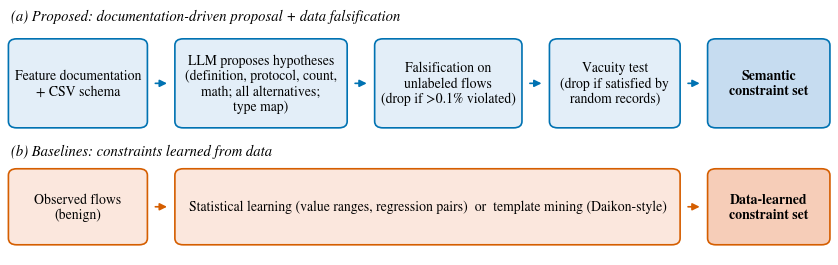

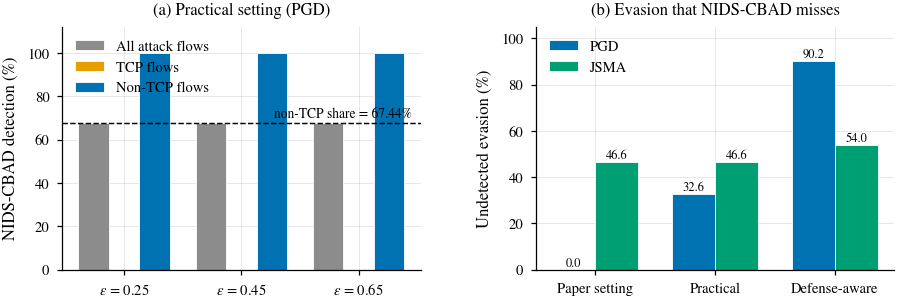

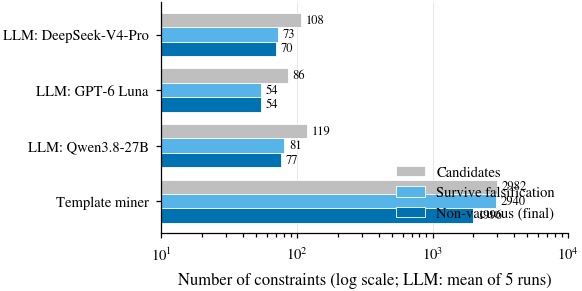

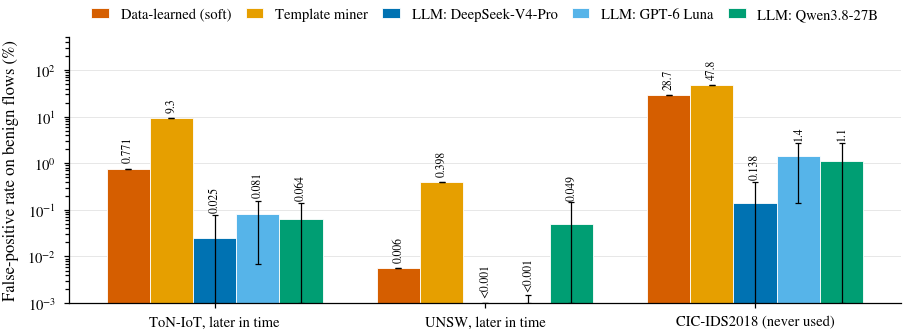

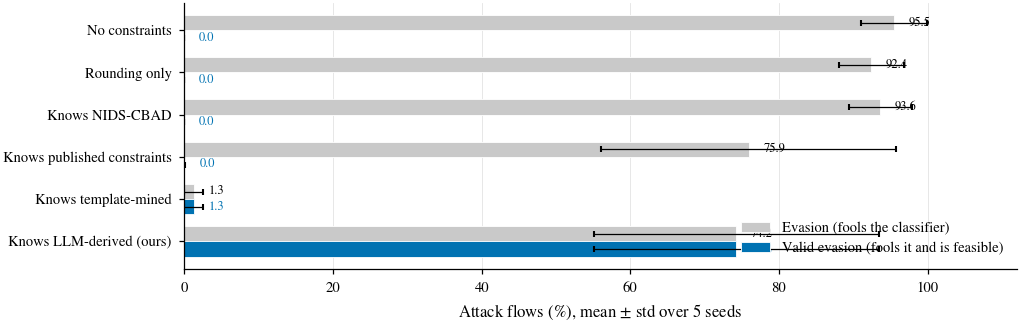

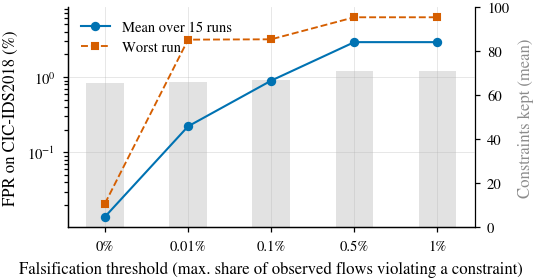

Saved figures: ['fig1_pipeline.pdf', 'fig1_pipeline.png', 'fig2_cbad.pdf', 'fig2_cbad.png', 'fig3_funnel.pdf', 'fig3_funnel.png', 'fig4_transfer_fpr.pdf', 'fig4_transfer_fpr.png', 'fig5_adaptive_attackers.pdf', 'fig5_adaptive_attackers.png', 'fig6_threshold_sensitivity.pdf', 'fig6_threshold_sensitivity.png']
Cell 19 finished: publication figures saved as PDF (vector) and 600-dpi PNG.


In [ ]:
# Cell 19 - Publication figures: IEEE style (Times-like serif fonts, Okabe-Ito colorblind-safe palette, column widths), each saved as vector PDF and 600-dpi PNG, built only from the saved result files

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

FIG = os.path.join(V2_DIR, 'figures')
os.makedirs(FIG, exist_ok=True)
mpl.rcParams.update({
    'font.family': 'serif', 'font.serif': ['STIXGeneral', 'DejaVu Serif'], 'mathtext.fontset': 'stix',
    'font.size': 8, 'axes.titlesize': 8, 'axes.labelsize': 8, 'xtick.labelsize': 7, 'ytick.labelsize': 7,
    'legend.fontsize': 7, 'axes.linewidth': 0.6, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
    'xtick.major.size': 2.5, 'ytick.major.size': 2.5, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.linewidth': 0.4, 'grid.alpha': 0.35, 'axes.axisbelow': True, 'legend.frameon': False,
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02, 'figure.dpi': 150})
COL1, COL2 = 3.5, 7.16  # IEEE single- and double-column widths (inches)
OI = {'blue': '#0072B2', 'orange': '#E69F00', 'green': '#009E73', 'red': '#D55E00',
      'purple': '#CC79A7', 'sky': '#56B4E9', 'grey': '#8C8C8C', 'black': '#000000'}

def save(fig, name):
    fig.savefig(os.path.join(FIG, f'{name}.pdf'))
    fig.savefig(os.path.join(FIG, f'{name}.png'), dpi=600)
    plt.show()
    plt.close(fig)

def fmt(v):
    return '<0.001' if v < 0.001 else (f'{v:.3f}' if v < 1 else f'{v:.1f}')

SRC_NAMES = {'Soft (ranges + CBAD pairs)': 'Data-learned (soft)', 'Template miner (no LLM)': 'Template miner',
             'LLM deepseek-v4-pro-0813': 'LLM: DeepSeek-V4-Pro', 'LLM gpt-6-luna': 'LLM: GPT-6 Luna',
             'LLM qwen3.8-27b': 'LLM: Qwen3.8-27B'}
SRC_COLORS = {'Data-learned (soft)': OI['red'], 'Template miner': OI['orange'], 'LLM: DeepSeek-V4-Pro': OI['blue'],
              'LLM: GPT-6 Luna': OI['sky'], 'LLM: Qwen3.8-27B': OI['green']}

# ---------- Figure 1: pipeline ----------
fig, ax = plt.subplots(figsize=(COL2, 2.25))
ax.set_xlim(0, 100); ax.set_ylim(0, 40); ax.axis('off')

def box(x, y, w, h, text, fc, ec, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.35,rounding_size=1.0', fc=fc, ec=ec, lw=0.8))
    ax.text(x + w / 2, y + h / 2, text, ha='center', va='center', fontsize=6.6, weight='bold' if bold else 'normal')

def arrow(x1, x2, y, color):
    ax.add_patch(FancyArrowPatch((x1, y), (x2, y), arrowstyle='-|>', mutation_scale=7, lw=0.8, color=color))

top = [(1, 16, 'Feature documentation\n+ CSV schema'),
       (21, 20, 'LLM proposes hypotheses\n(definition, protocol, count,\nmath; all alternatives;\ntype map)'),
       (45, 17, 'Falsification on\nunlabeled flows\n(drop if >0.1% violated)'),
       (66, 15, 'Vacuity test\n(drop if satisfied by\nrandom records)'),
       (85, 14, 'Semantic\nconstraint set')]
for i, (x, w, t) in enumerate(top):
    box(x, 21, w, 13, t, '#E3EEF8' if i < 4 else '#C6DCF0', OI['blue'], bold=(i == 4))
    if i:
        px, pw, _ = top[i - 1]
        arrow(px + pw + 0.8, x - 0.8, 27.5, OI['blue'])
bottom = [(1, 16, 'Observed flows\n(benign)'),
          (21, 60, 'Statistical learning (value ranges, regression pairs)  or  template mining (Daikon-style)'),
          (85, 14, 'Data-learned\nconstraint set')]
for i, (x, w, t) in enumerate(bottom):
    box(x, 3, w, 11, t, '#FBE7DD' if i < 2 else '#F6CDB8', OI['red'], bold=(i == 2))
    if i:
        px, pw, _ = bottom[i - 1]
        arrow(px + pw + 0.8, x - 0.8, 8.5, OI['red'])
ax.text(1, 37.2, '(a) Proposed: documentation-driven proposal + data falsification', fontsize=7, style='italic')
ax.text(1, 16.4, '(b) Baselines: constraints learned from data', fontsize=7, style='italic')
save(fig, 'fig1_pipeline')

# ---------- Figure 2: NIDS-CBAD ----------
f2 = pd.read_csv(os.path.join(RES, 'fig2_cbad_eps_protocol.csv'))
t3 = pd.read_csv(os.path.join(RES, 'table3_cbad_attacks.csv'))
fig, (a, b) = plt.subplots(1, 2, figsize=(COL2, 2.1), gridspec_kw={'wspace': 0.32})
eps_vals = sorted(f2['eps'].unique()); w = 0.26; xs = np.arange(len(eps_vals))
for k, (flows, col, lab) in enumerate([('all', OI['grey'], 'All attack flows'), ('TCP', OI['orange'], 'TCP flows'),
                                       ('non-TCP', OI['blue'], 'Non-TCP flows')]):
    vals = [f2[(f2.eps == e) & (f2.flows == flows)]['CBAD_detection_%'].iloc[0] for e in eps_vals]
    a.bar(xs + (k - 1) * w, vals, w, color=col, label=lab, edgecolor='white', lw=0.4)
share = f2[(f2.eps == eps_vals[0]) & (f2.flows == 'all')]['CBAD_detection_%'].iloc[0]
a.axhline(share, color=OI['black'], ls='--', lw=0.7)
a.text(len(eps_vals) - 0.55, share + 3, f'non-TCP share = {share:.2f}%', ha='right', fontsize=6.5)
a.set_xticks(xs); a.set_xticklabels([f'$\\epsilon$ = {e:g}' for e in eps_vals])
a.set_ylabel('NIDS-CBAD detection (%)'); a.set_ylim(0, 112)
a.set_title('(a) Practical setting (PGD)'); a.legend(loc='upper left', ncol=1)

settings = ['paper', 'practical', 'aware']; atks = ['PGD', 'JSMA']; xs = np.arange(len(settings)); w = 0.36
for k, (atk, col) in enumerate(zip(atks, [OI['blue'], OI['green']])):
    vals = [t3[(t3.setting == s) & (t3.attack == atk)]['undetected_evasion_%'].iloc[0] for s in settings]
    bars = b.bar(xs + (k - 0.5) * w, vals, w, color=col, label=atk, edgecolor='white', lw=0.4)
    for r, v in zip(bars, vals):
        b.text(r.get_x() + r.get_width() / 2, v + 1.5, f'{v:.1f}', ha='center', fontsize=6)
b.set_xticks(xs); b.set_xticklabels(['Paper setting', 'Practical', 'Defense-aware'])
b.set_ylabel('Undetected evasion (%)'); b.set_ylim(0, 105)
b.set_title('(b) Evasion that NIDS-CBAD misses'); b.legend(loc='upper left')
save(fig, 'fig2_cbad')

# ---------- Figure 3: funnel ----------
t5 = pd.read_csv(os.path.join(RES, 'table5_transfer_detail.csv'))
t5['name'] = t5['source'].map(SRC_NAMES)
order = ['LLM: DeepSeek-V4-Pro', 'LLM: GPT-6 Luna', 'LLM: Qwen3.8-27B', 'Template miner']
fun = t5[t5['name'].isin(order)].groupby('name')[['candidates', 'survived', 'hard']].mean().reindex(order)
fig, ax = plt.subplots(figsize=(COL1, 2.0))
ys = np.arange(len(order)); h = 0.26
for k, (stage, col, lab) in enumerate([('candidates', '#BFBFBF', 'Candidates'), ('survived', OI['sky'], 'Survive falsification'),
                                       ('hard', OI['blue'], 'Non-vacuous (final)')]):
    ax.barh(ys + (k - 1) * h, fun[stage], h, color=col, label=lab, edgecolor='white', lw=0.4)
    for y, v in zip(ys, fun[stage]):
        ax.text(v * 1.08, y + (k - 1) * h, f'{v:.0f}', va='center', fontsize=6)
ax.set_xscale('log'); ax.set_xlim(10, 10000)
ax.set_yticks(ys); ax.set_yticklabels(order); ax.invert_yaxis()
ax.set_xlabel('Number of constraints (log scale; LLM: mean of 5 runs)')
ax.legend(loc='lower right'); ax.grid(axis='y', visible=False)
save(fig, 'fig3_funnel')

# ---------- Figure 4: false positives across time and networks ----------
evals = ['FPR ToN-IoT later %', 'FPR UNSW later %', 'FPR CIC (never used) %']
elabels = ['ToN-IoT, later in time', 'UNSW, later in time', 'CIC-IDS2018 (never used)']
srcs = ['Data-learned (soft)', 'Template miner', 'LLM: DeepSeek-V4-Pro', 'LLM: GPT-6 Luna', 'LLM: Qwen3.8-27B']
mean = t5.groupby('name')[evals].mean().reindex(srcs)
std = t5.groupby('name')[evals].std().reindex(srcs).fillna(0)
fig, ax = plt.subplots(figsize=(COL2, 2.3))
xs = np.arange(len(evals)); w = 0.16; floor = 1e-3
for k, s in enumerate(srcs):
    m = np.maximum(mean.loc[s].values, floor)
    e = std.loc[s].values
    lo = np.minimum(e, m - floor)
    bars = ax.bar(xs + (k - 2) * w, m, w, color=SRC_COLORS[s], label=s, edgecolor='white', lw=0.4,
                  yerr=[lo, e], capsize=1.5, error_kw={'lw': 0.6, 'capthick': 0.6})
    for r, v, ee in zip(bars, mean.loc[s].values, e):
        ax.text(r.get_x() + r.get_width() / 2, max(v, floor) * 1.35 + ee, fmt(v), ha='center', va='bottom',
                fontsize=5.6, rotation=90)
ax.set_yscale('log'); ax.set_ylim(floor, 500)
ax.set_xticks(xs); ax.set_xticklabels(elabels)
ax.set_ylabel('False-positive rate on benign flows (%)')
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, 1.16), handlelength=1.2, columnspacing=1.0)
ax.grid(axis='x', visible=False)
save(fig, 'fig4_transfer_fpr')

# ---------- Figure 5: adaptive attackers (5 seeds) ----------
t6 = pd.read_csv(os.path.join(RES, 'table6_seeds_detail.csv'))
att_order = ['None (unconstrained)', 'Rounding only', 'NIDS-CBAD aware', 'Reference (published) aware',
             'Template miner aware', 'LLM all models aware']
att_names = ['No constraints', 'Rounding only', 'Knows NIDS-CBAD', 'Knows published constraints',
             'Knows template-mined', 'Knows LLM-derived (ours)']
g = t6.groupby('attacker')[['evasion_%', 'valid evasion|LLM all %']].agg(['mean', 'std']).reindex(att_order)
fig, ax = plt.subplots(figsize=(COL2, 2.3))
ys = np.arange(len(att_order)); h = 0.36
ax.barh(ys - h / 2, g[('evasion_%', 'mean')], h, xerr=g[('evasion_%', 'std')], color='#C9C9C9',
        label='Evasion (fools the classifier)', edgecolor='white', lw=0.4, error_kw={'lw': 0.6, 'capsize': 1.5})
ax.barh(ys + h / 2, g[('valid evasion|LLM all %', 'mean')], h, xerr=g[('valid evasion|LLM all %', 'std')],
        color=OI['blue'], label='Valid evasion (fools it and is feasible)', edgecolor='white', lw=0.4,
        error_kw={'lw': 0.6, 'capsize': 1.5})
for y, (ev, vv) in enumerate(zip(g[('evasion_%', 'mean')], g[('valid evasion|LLM all %', 'mean')])):
    ax.text(ev + 2, y - h / 2, f'{ev:.1f}', va='center', fontsize=6)
    ax.text(vv + 2, y + h / 2, f'{vv:.1f}', va='center', fontsize=6, color=OI['blue'])
ax.set_yticks(ys); ax.set_yticklabels(att_names); ax.invert_yaxis()
ax.set_xlim(0, 112); ax.set_xlabel('Attack flows (%), mean $\\pm$ std over 5 seeds')
ax.legend(loc='lower right'); ax.grid(axis='y', visible=False)
save(fig, 'fig5_adaptive_attackers')

# ---------- Figure 6: falsification-threshold sensitivity ----------
t8 = pd.read_csv(os.path.join(RES, 'table8_sensitivity.csv'))
ft = t8[t8['analysis'] == 'falsification threshold']
fig, ax = plt.subplots(figsize=(COL1, 1.9))
xs = np.arange(len(ft))
ax.plot(xs, np.maximum(ft['FPR CIC mean %'], floor), 'o-', color=OI['blue'], lw=1.0, ms=3.5, label='Mean over 15 runs')
ax.plot(xs, np.maximum(ft['FPR CIC max %'], floor), 's--', color=OI['red'], lw=0.9, ms=3.2, label='Worst run')
ax.set_yscale('log'); ax.set_xticks(xs); ax.set_xticklabels(ft['setting'])
ax.set_xlabel('Falsification threshold (max. share of observed flows violating a constraint)')
ax.set_ylabel('FPR on CIC-IDS2018 (%)')
ax2 = ax.twinx()
ax2.bar(xs, ft['n_mean'], 0.45, color=OI['grey'], alpha=0.25, zorder=0)
ax2.set_ylabel('Constraints kept (mean)', color=OI['grey']); ax2.set_ylim(0, 100)
ax2.spines['right'].set_visible(True); ax2.grid(False)
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
ax.legend(loc='upper left')
save(fig, 'fig6_threshold_sensitivity')

print('Saved figures:', sorted(os.listdir(FIG)))
print('Cell 19 finished: publication figures saved as PDF (vector) and 600-dpi PNG.')

[fig1_pipeline] overlaps: 0


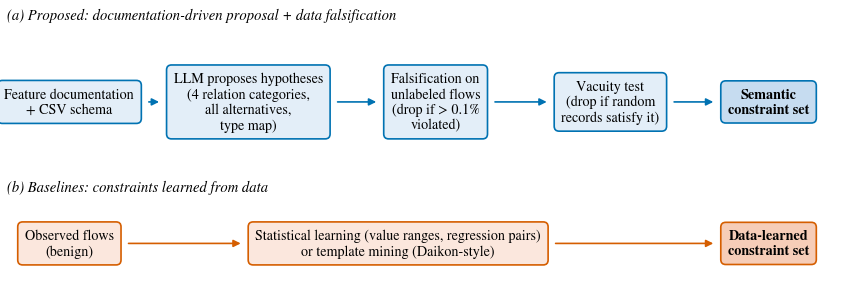

[fig2_cbad] overlaps: 0


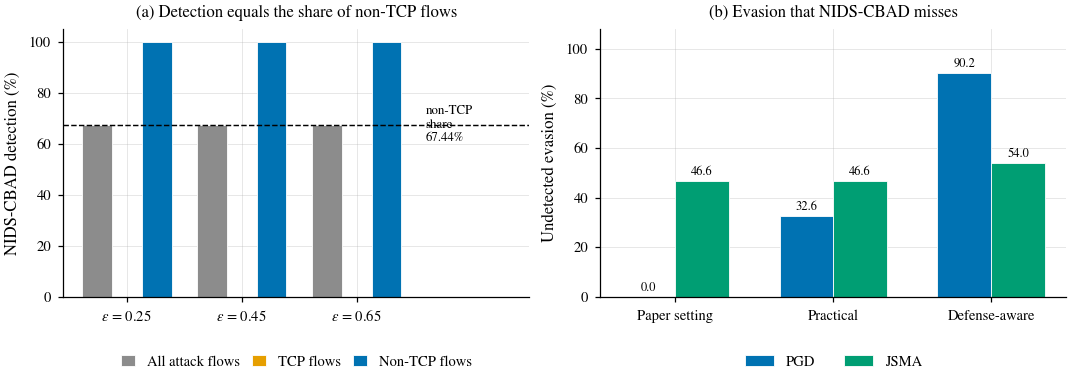

[fig3_funnel] overlaps: 4 -> 'LLM: DeepSeek-V4-Pro' x 'bar'; 'LLM: GPT-6 Luna' x 'bar'; 'LLM: Qwen3.8-27B' x 'bar'; 'Template miner' x 'bar'


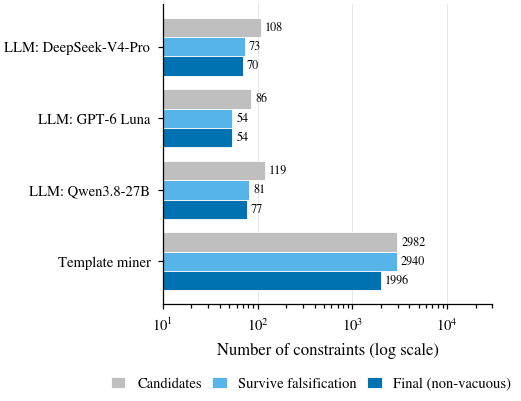

[fig4_transfer_fpr] overlaps: 0


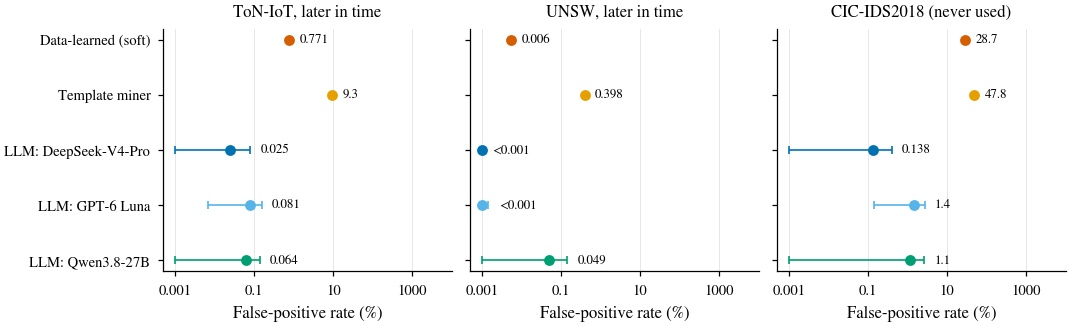

[fig5_adaptive_attackers] overlaps: 0


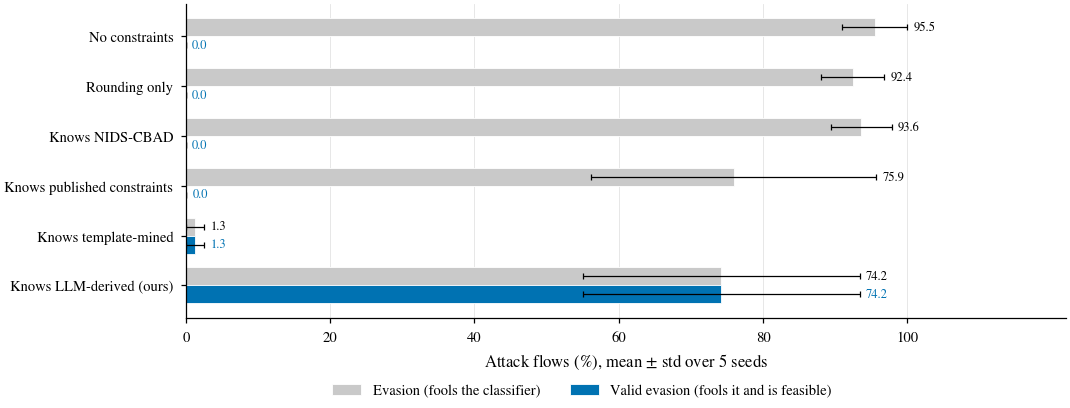

[fig6_threshold_sensitivity] overlaps: 3 -> '$\\mathdefault{10^{-4}}$' x 'Constraints kept'; '$\\mathdefault{10^{-4}}$' x '50'; '$\\mathdefault{10^{-3}}$' x '100'


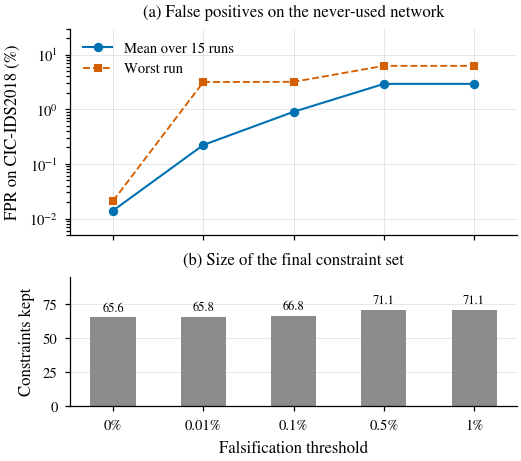


Saved files: ['fig1_pipeline.pdf', 'fig1_pipeline.png', 'fig1_pipeline.tiff', 'fig2_cbad.pdf', 'fig2_cbad.png', 'fig2_cbad.tiff', 'fig3_funnel.pdf', 'fig3_funnel.png', 'fig3_funnel.tiff', 'fig4_transfer_fpr.pdf', 'fig4_transfer_fpr.png', 'fig4_transfer_fpr.tiff', 'fig5_adaptive_attackers.pdf', 'fig5_adaptive_attackers.png', 'fig5_adaptive_attackers.tiff', 'fig6_threshold_sensitivity.pdf', 'fig6_threshold_sensitivity.png', 'fig6_threshold_sensitivity.tiff']
Cell 19 finished: publication figures saved (PDF vector, PNG and TIFF at 600 dpi) with an overlap check.


In [ ]:
# Cell 19 - Publication figures (rewritten): auto-sized diagram boxes, legends outside the plotting area, dot plot for the transfer figure, stacked panels instead of twin axes, an automatic text-overlap check, and export as vector PDF plus 600-dpi PNG and TIFF

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

FIG = os.path.join(V2_DIR, 'figures')
os.makedirs(FIG, exist_ok=True)
mpl.rcParams.update({
    'font.family': 'serif', 'font.serif': ['STIXGeneral', 'DejaVu Serif'], 'mathtext.fontset': 'stix',
    'font.size': 8, 'axes.titlesize': 8, 'axes.labelsize': 8, 'xtick.labelsize': 7, 'ytick.labelsize': 7,
    'legend.fontsize': 7, 'axes.linewidth': 0.6, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
    'xtick.major.size': 2.5, 'ytick.major.size': 2.5, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.linewidth': 0.4, 'grid.alpha': 0.35, 'axes.axisbelow': True, 'legend.frameon': False,
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.03, 'figure.dpi': 150})
COL1, COL2 = 3.5, 7.16  # IEEE single- and double-column widths (inches)
OI = {'blue': '#0072B2', 'orange': '#E69F00', 'green': '#009E73', 'red': '#D55E00',
      'purple': '#CC79A7', 'sky': '#56B4E9', 'grey': '#8C8C8C', 'black': '#000000'}
SRC_NAMES = {'Soft (ranges + CBAD pairs)': 'Data-learned (soft)', 'Template miner (no LLM)': 'Template miner',
             'LLM deepseek-v4-pro-0813': 'LLM: DeepSeek-V4-Pro', 'LLM gpt-6-luna': 'LLM: GPT-6 Luna',
             'LLM qwen3.8-27b': 'LLM: Qwen3.8-27B'}
SRC_COLORS = {'Data-learned (soft)': OI['red'], 'Template miner': OI['orange'], 'LLM: DeepSeek-V4-Pro': OI['blue'],
              'LLM: GPT-6 Luna': OI['sky'], 'LLM: Qwen3.8-27B': OI['green']}
FLOOR = 1e-3

def fmt(v):
    return '<0.001' if v < 0.001 else (f'{v:.3f}' if v < 1 else f'{v:.1f}')

def overlap_report(fig, name):
    # Pairwise overlap check of every visible text, legend and bar in the figure (display coordinates)
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    items = []
    for ax in fig.axes:
        texts = list(ax.texts) + [ax.title, ax.xaxis.label, ax.yaxis.label] + \
                [t for t in ax.get_xticklabels() + ax.get_yticklabels() if t.get_text()]
        for t in texts:
            if t.get_visible() and t.get_text():
                bb = t.get_bbox_patch().get_window_extent(r) if t.get_bbox_patch() else t.get_window_extent(r)
                items.append(('text', t.get_text().replace('\n', ' ')[:28], bb, id(ax)))
        if ax.get_legend():
            items.append(('legend', 'legend', ax.get_legend().get_window_extent(r), id(ax)))
        for p in ax.patches:
            if isinstance(p, Rectangle) and p.get_height() > 0 and p.get_width() > 0 and p.get_visible():
                items.append(('bar', 'bar', p.get_window_extent(r), id(ax)))
    for lg in fig.legends:
        items.append(('legend', 'figure legend', lg.get_window_extent(r), None))
    clashes = []
    for i in range(len(items)):
        for j in range(i + 1, len(items)):
            a, b = items[i], items[j]
            if a[0] == 'bar' and b[0] == 'bar':
                continue
            if a[2].overlaps(b[2]) and a[2].width > 0 and b[2].width > 0:
                inter_w = min(a[2].x1, b[2].x1) - max(a[2].x0, b[2].x0)
                inter_h = min(a[2].y1, b[2].y1) - max(a[2].y0, b[2].y0)
                if inter_w > 1 and inter_h > 1:  # ignore touching edges (< 1 pixel)
                    clashes.append(f'{a[1]!r} x {b[1]!r}')
    print(f'[{name}] overlaps: {len(clashes)}' + ('' if not clashes else ' -> ' + '; '.join(clashes[:6])))

def save(fig, name):
    overlap_report(fig, name)
    fig.savefig(os.path.join(FIG, f'{name}.pdf'))
    fig.savefig(os.path.join(FIG, f'{name}.png'), dpi=600)
    fig.savefig(os.path.join(FIG, f'{name}.tiff'), dpi=600, pil_kwargs={'compression': 'tiff_lzw'})
    plt.show()
    plt.close(fig)

# ---------- Figure 1: pipeline (boxes sized by their text, arrows drawn between measured edges) ----------
fig, ax = plt.subplots(figsize=(COL2, 2.5))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')

def node(x, y, text, fc, ec, bold=False):
    return ax.text(x, y, text, ha='center', va='center', fontsize=6.8, weight='bold' if bold else 'normal',
                   bbox=dict(boxstyle='round,pad=0.5,rounding_size=0.35', fc=fc, ec=ec, lw=0.8), zorder=3)

top_txt = ['Feature documentation\n+ CSV schema',
           'LLM proposes hypotheses\n(4 relation categories,\nall alternatives,\ntype map)',
           'Falsification on\nunlabeled flows\n(drop if > 0.1%\nviolated)',
           'Vacuity test\n(drop if random\nrecords satisfy it)',
           'Semantic\nconstraint set']
bot_txt = ['Observed flows\n(benign)',
           'Statistical learning (value ranges, regression pairs)\nor template mining (Daikon-style)',
           'Data-learned\nconstraint set']
top = [node(x, 0.66, t, '#C6DCF0' if i == 4 else '#E3EEF8', OI['blue'], bold=(i == 4))
       for i, (x, t) in enumerate(zip([0.075, 0.29, 0.515, 0.725, 0.915], top_txt))]
bot = [node(x, 0.17, t, '#F6CDB8' if i == 2 else '#FBE7DD', OI['red'], bold=(i == 2))
       for i, (x, t) in enumerate(zip([0.075, 0.47, 0.915], bot_txt))]
ax.text(0.0, 0.985, '(a) Proposed: documentation-driven proposal + data falsification', fontsize=7, style='italic', va='top')
ax.text(0.0, 0.39, '(b) Baselines: constraints learned from data', fontsize=7, style='italic', va='top')

fig.canvas.draw()
rend = fig.canvas.get_renderer()
inv_t = ax.transData.inverted()
def edges(t):
    bb = t.get_bbox_patch().get_window_extent(rend)
    (x0, y0), (x1, y1) = inv_t.transform([(bb.x0, bb.y0), (bb.x1, bb.y1)])
    return x0, x1, (y0 + y1) / 2
for row, col in [(top, OI['blue']), (bot, OI['red'])]:
    for a_, b_ in zip(row[:-1], row[1:]):
        _, ax1, y = edges(a_)
        bx0, _, _ = edges(b_)
        if bx0 - ax1 < 0.01:
            print('WARNING: boxes too close in Figure 1')
        ax.annotate('', xy=(bx0 - 0.004, y), xytext=(ax1 + 0.004, y),
                    arrowprops=dict(arrowstyle='-|>', lw=0.8, color=col, mutation_scale=7))
save(fig, 'fig1_pipeline')

# ---------- Figure 2: NIDS-CBAD ----------
f2 = pd.read_csv(os.path.join(RES, 'fig2_cbad_eps_protocol.csv'))
t3 = pd.read_csv(os.path.join(RES, 'table3_cbad_attacks.csv'))
fig, (a, b) = plt.subplots(1, 2, figsize=(COL2, 2.55), layout='constrained')
eps_vals = sorted(f2['eps'].unique()); w = 0.26; xs = np.arange(len(eps_vals))
for k, (flows, col, lab) in enumerate([('all', OI['grey'], 'All attack flows'), ('TCP', OI['orange'], 'TCP flows'),
                                       ('non-TCP', OI['blue'], 'Non-TCP flows')]):
    vals = [f2[(f2.eps == e) & (f2.flows == flows)]['CBAD_detection_%'].iloc[0] for e in eps_vals]
    a.bar(xs + (k - 1) * w, vals, w, color=col, label=lab, edgecolor='white', lw=0.4)
share = f2[(f2.eps == eps_vals[0]) & (f2.flows == 'all')]['CBAD_detection_%'].iloc[0]
a.axhline(share, color=OI['black'], ls='--', lw=0.7)
a.set_xlim(-0.55, len(eps_vals) - 0.45 + 0.95)
a.text(len(eps_vals) - 0.45 + 0.05, share, f'non-TCP\nshare\n{share:.2f}%', fontsize=6.2, va='center', ha='left')
a.set_xticks(xs); a.set_xticklabels([f'$\\epsilon$ = {e:g}' for e in eps_vals])
a.set_ylabel('NIDS-CBAD detection (%)'); a.set_ylim(0, 105)
a.set_title('(a) Detection equals the share of non-TCP flows')
a.legend(loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=3, handlelength=1.0, columnspacing=0.8)

settings = ['paper', 'practical', 'aware']; atks = ['PGD', 'JSMA']; xs = np.arange(len(settings)); w = 0.34
for k, (atk, col) in enumerate(zip(atks, [OI['blue'], OI['green']])):
    vals = [t3[(t3.setting == s) & (t3.attack == atk)]['undetected_evasion_%'].iloc[0] for s in settings]
    bars = b.bar(xs + (k - 0.5) * w, vals, w, color=col, label=atk, edgecolor='white', lw=0.4)
    for rr, v in zip(bars, vals):
        b.annotate(f'{v:.1f}', (rr.get_x() + rr.get_width() / 2, v), xytext=(0, 1.5), textcoords='offset points',
                   ha='center', va='bottom', fontsize=6)
b.set_xticks(xs); b.set_xticklabels(['Paper setting', 'Practical', 'Defense-aware'])
b.set_ylabel('Undetected evasion (%)'); b.set_ylim(0, 108)
b.set_title('(b) Evasion that NIDS-CBAD misses')
b.legend(loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=2)
save(fig, 'fig2_cbad')

# ---------- Figure 3: funnel ----------
t5 = pd.read_csv(os.path.join(RES, 'table5_transfer_detail.csv'))
t5['name'] = t5['source'].map(SRC_NAMES)
order = ['LLM: DeepSeek-V4-Pro', 'LLM: GPT-6 Luna', 'LLM: Qwen3.8-27B', 'Template miner']
fun = t5[t5['name'].isin(order)].groupby('name')[['candidates', 'survived', 'hard']].mean().reindex(order)
fig, ax = plt.subplots(figsize=(COL1, 2.7), layout='constrained')
ys = np.arange(len(order)); h = 0.27
for k, (stage, col, lab) in enumerate([('candidates', '#BFBFBF', 'Candidates'), ('survived', OI['sky'], 'Survive falsification'),
                                       ('hard', OI['blue'], 'Final (non-vacuous)')]):
    ax.barh(ys + (k - 1) * h, fun[stage], h, color=col, label=lab, edgecolor='white', lw=0.4)
    for y, v in zip(ys, fun[stage]):
        ax.annotate(f'{v:.0f}', (v, y + (k - 1) * h), xytext=(2, 0), textcoords='offset points',
                    va='center', ha='left', fontsize=5.8)
ax.set_xscale('log'); ax.set_xlim(10, 30000)
ax.set_yticks(ys); ax.set_yticklabels(order); ax.invert_yaxis()
ax.set_xlabel('Number of constraints (log scale)')
ax.legend(loc='upper center', bbox_to_anchor=(0.45, -0.2), ncol=3, handlelength=1.0, columnspacing=0.7)
ax.grid(axis='y', visible=False)
save(fig, 'fig3_funnel')

# ---------- Figure 4: false positives across time and networks (dot plot, one panel per evaluation set) ----------
evals = ['FPR ToN-IoT later %', 'FPR UNSW later %', 'FPR CIC (never used) %']
elabels = ['ToN-IoT, later in time', 'UNSW, later in time', 'CIC-IDS2018 (never used)']
srcs = ['Data-learned (soft)', 'Template miner', 'LLM: DeepSeek-V4-Pro', 'LLM: GPT-6 Luna', 'LLM: Qwen3.8-27B']
mean = t5.groupby('name')[evals].mean().reindex(srcs)
std = t5.groupby('name')[evals].std().reindex(srcs).fillna(0)
fig, axes = plt.subplots(1, 3, figsize=(COL2, 2.2), sharey=True, layout='constrained')
for ax, e, lab in zip(axes, evals, elabels):
    for i, s in enumerate(srcs):
        m, sd = mean.loc[s, e], std.loc[s, e]
        mv = max(m, FLOOR)
        ax.errorbar(mv, i, xerr=[[min(sd, mv - FLOOR)], [sd]], fmt='o', color=SRC_COLORS[s], ms=4.2,
                    elinewidth=0.8, capsize=2, capthick=0.8)
        ax.annotate(fmt(m), (mv + sd, i), xytext=(5, 0), textcoords='offset points', va='center', ha='left', fontsize=6.2)
    ax.set_xscale('log'); ax.set_xlim(5e-4, 1e4)
    ax.set_xticks([1e-3, 1e-1, 1e1, 1e3]); ax.set_xticklabels(['0.001', '0.1', '10', '1000'])
    ax.set_title(lab); ax.set_xlabel('False-positive rate (%)')
    ax.grid(axis='y', visible=False)
axes[0].set_yticks(range(len(srcs))); axes[0].set_yticklabels(srcs); axes[0].invert_yaxis()
save(fig, 'fig4_transfer_fpr')

# ---------- Figure 5: adaptive attackers over 5 seeds ----------
t6 = pd.read_csv(os.path.join(RES, 'table6_seeds_detail.csv'))
att_order = ['None (unconstrained)', 'Rounding only', 'NIDS-CBAD aware', 'Reference (published) aware',
             'Template miner aware', 'LLM all models aware']
att_names = ['No constraints', 'Rounding only', 'Knows NIDS-CBAD', 'Knows published constraints',
             'Knows template-mined', 'Knows LLM-derived (ours)']
g = t6.groupby('attacker')[['evasion_%', 'valid evasion|LLM all %']].agg(['mean', 'std']).reindex(att_order)
fig, ax = plt.subplots(figsize=(COL2, 2.75), layout='constrained')
ys = np.arange(len(att_order)); h = 0.36
for off, colname, col, lab in [(-h / 2, 'evasion_%', '#C9C9C9', 'Evasion (fools the classifier)'),
                               (h / 2, 'valid evasion|LLM all %', OI['blue'], 'Valid evasion (fools it and is feasible)')]:
    mv, sv = g[(colname, 'mean')].values, g[(colname, 'std')].fillna(0).values
    ax.barh(ys + off, mv, h, xerr=sv, color=col, label=lab, edgecolor='white', lw=0.4,
            error_kw={'lw': 0.6, 'capsize': 1.5, 'capthick': 0.6})
    for y, v, s_ in zip(ys, mv, sv):
        ax.annotate(f'{v:.1f}', (v + s_, y + off), xytext=(3, 0), textcoords='offset points', va='center', ha='left',
                    fontsize=6, color=OI['blue'] if col == OI['blue'] else OI['black'])
ax.set_yticks(ys); ax.set_yticklabels(att_names); ax.invert_yaxis()
ax.set_xlim(0, 122); ax.set_xticks(range(0, 101, 20))
ax.set_xlabel('Attack flows (%), mean $\\pm$ std over 5 seeds')
ax.legend(loc='upper center', bbox_to_anchor=(0.45, -0.17), ncol=2)
ax.grid(axis='y', visible=False)
save(fig, 'fig5_adaptive_attackers')

# ---------- Figure 6: falsification-threshold sensitivity (two stacked panels) ----------
t8 = pd.read_csv(os.path.join(RES, 'table8_sensitivity.csv'))
ft = t8[t8['analysis'] == 'falsification threshold'].reset_index(drop=True)
fig, (a, b) = plt.subplots(2, 1, figsize=(COL1, 3.1), sharex=True, layout='constrained',
                           gridspec_kw={'height_ratios': [1.6, 1]})
xs = np.arange(len(ft))
a.plot(xs, np.maximum(ft['FPR CIC mean %'], FLOOR), 'o-', color=OI['blue'], lw=1.0, ms=3.5, label='Mean over 15 runs')
a.plot(xs, np.maximum(ft['FPR CIC max %'], FLOOR), 's--', color=OI['red'], lw=0.9, ms=3.2, label='Worst run')
a.set_yscale('log'); a.set_ylim(5e-3, 30)
a.set_ylabel('FPR on CIC-IDS2018 (%)')
a.legend(loc='upper left')
a.set_title('(a) False positives on the never-used network')
b.bar(xs, ft['n_mean'], 0.5, color=OI['grey'])
for x, v in zip(xs, ft['n_mean']):
    b.annotate(f'{v:.1f}', (x, v), xytext=(0, 1.5), textcoords='offset points', ha='center', va='bottom', fontsize=6)
b.set_ylim(0, 95); b.set_ylabel('Constraints kept')
b.set_title('(b) Size of the final constraint set')
b.set_xticks(xs); b.set_xticklabels(ft['setting']); b.set_xlabel('Falsification threshold')
b.grid(axis='x', visible=False)
save(fig, 'fig6_threshold_sensitivity')

print('\nSaved files:', sorted(os.listdir(FIG)))
print('Cell 19 finished: publication figures saved (PDF vector, PNG and TIFF at 600 dpi) with an overlap check.')

[fig1_pipeline] elements outside the canvas: 0
[fig1_pipeline] overlaps: 0


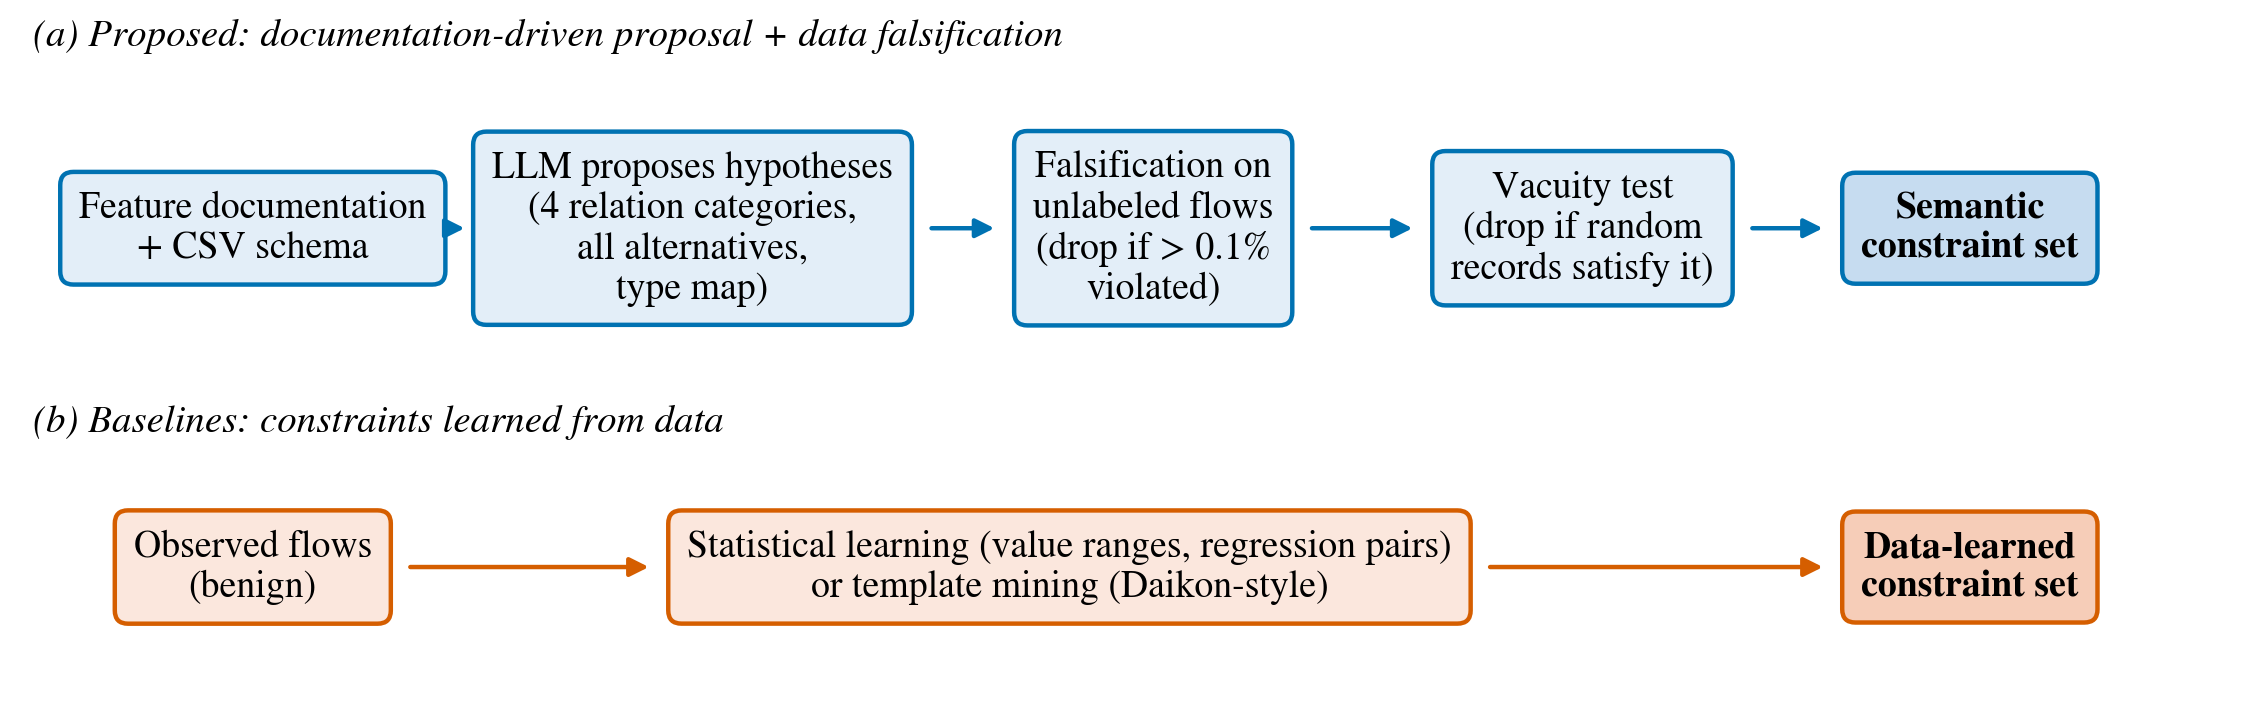

[fig2_cbad] elements outside the canvas: 0
[fig2_cbad] overlaps: 0


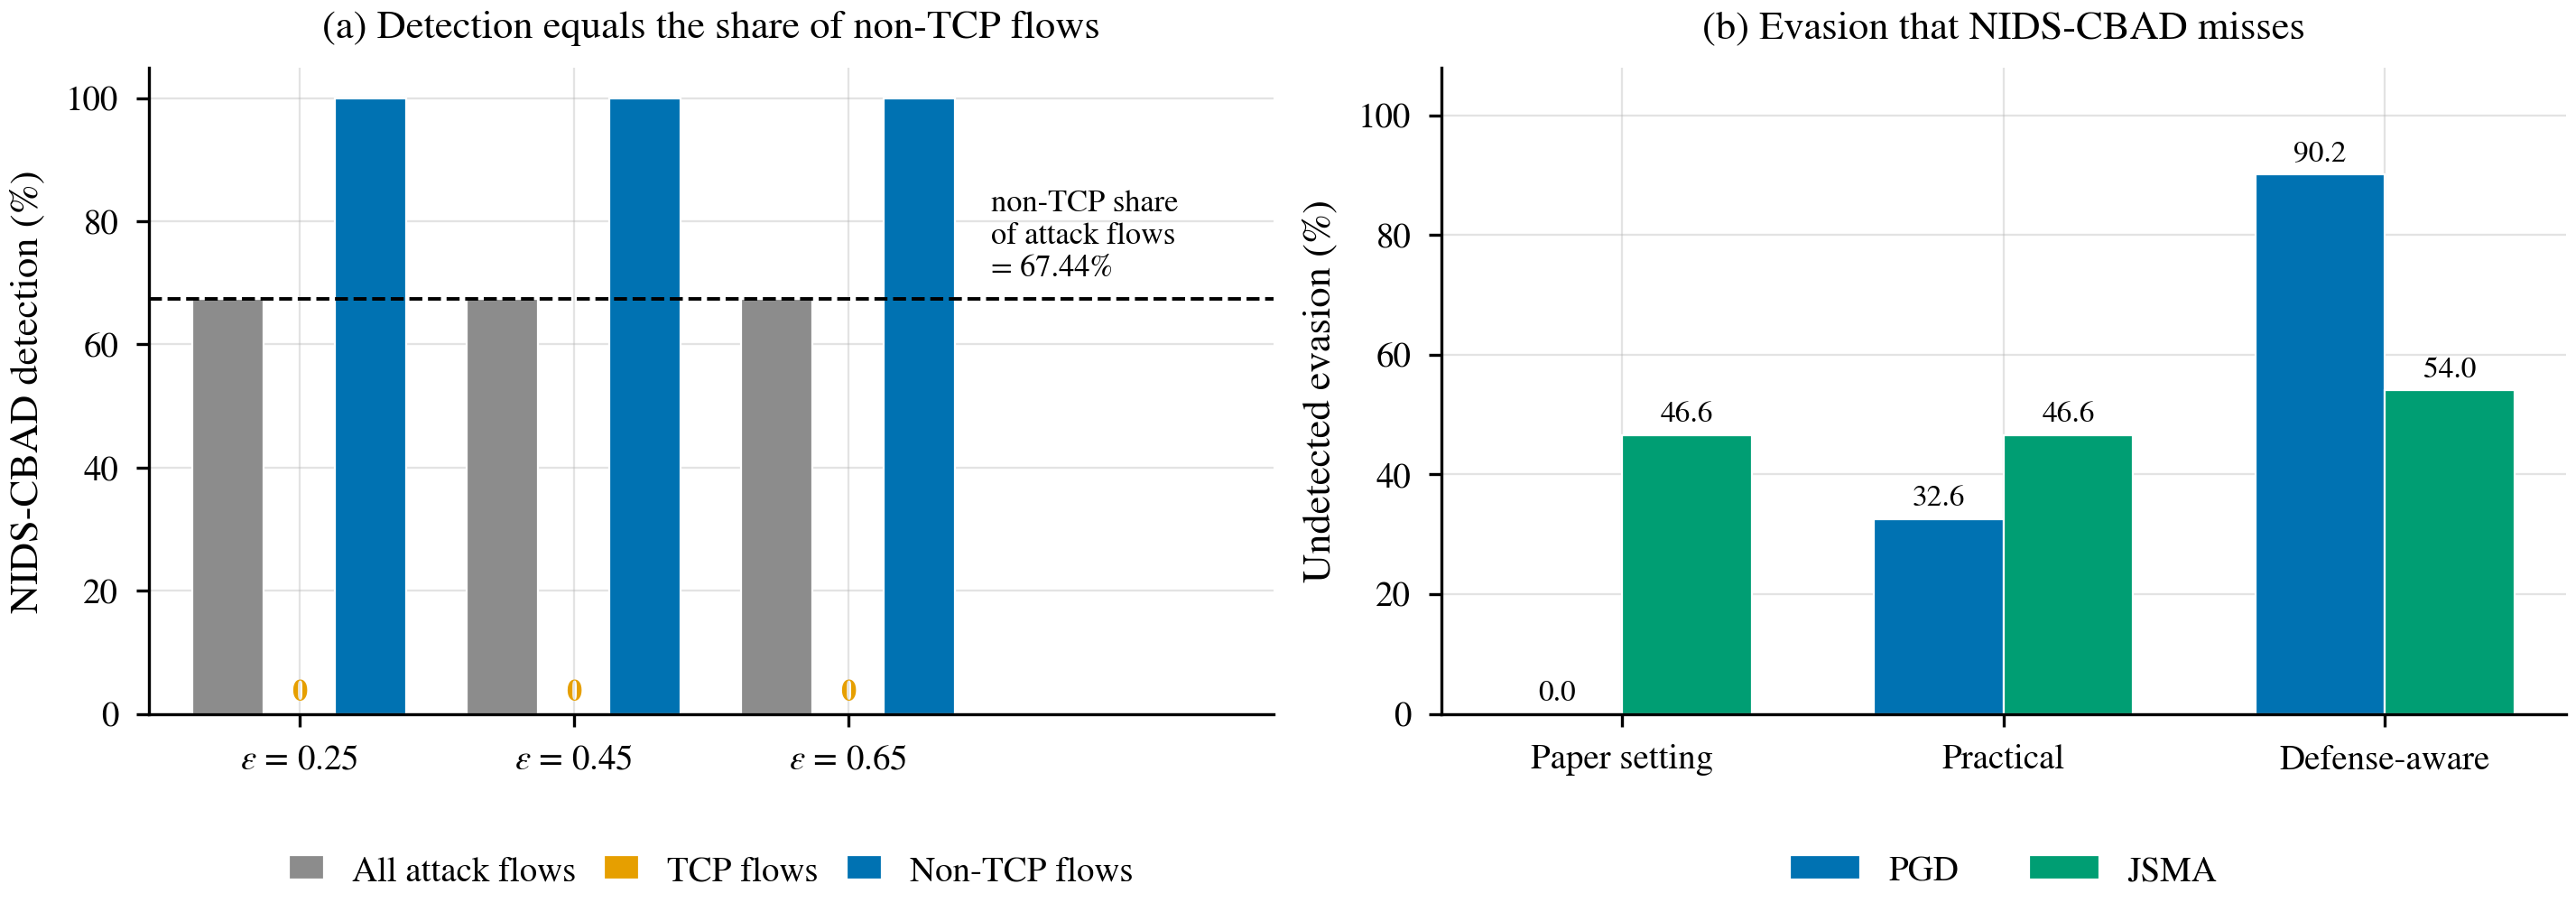

[fig5_adaptive_attackers] elements outside the canvas: 0
[fig5_adaptive_attackers] overlaps: 0


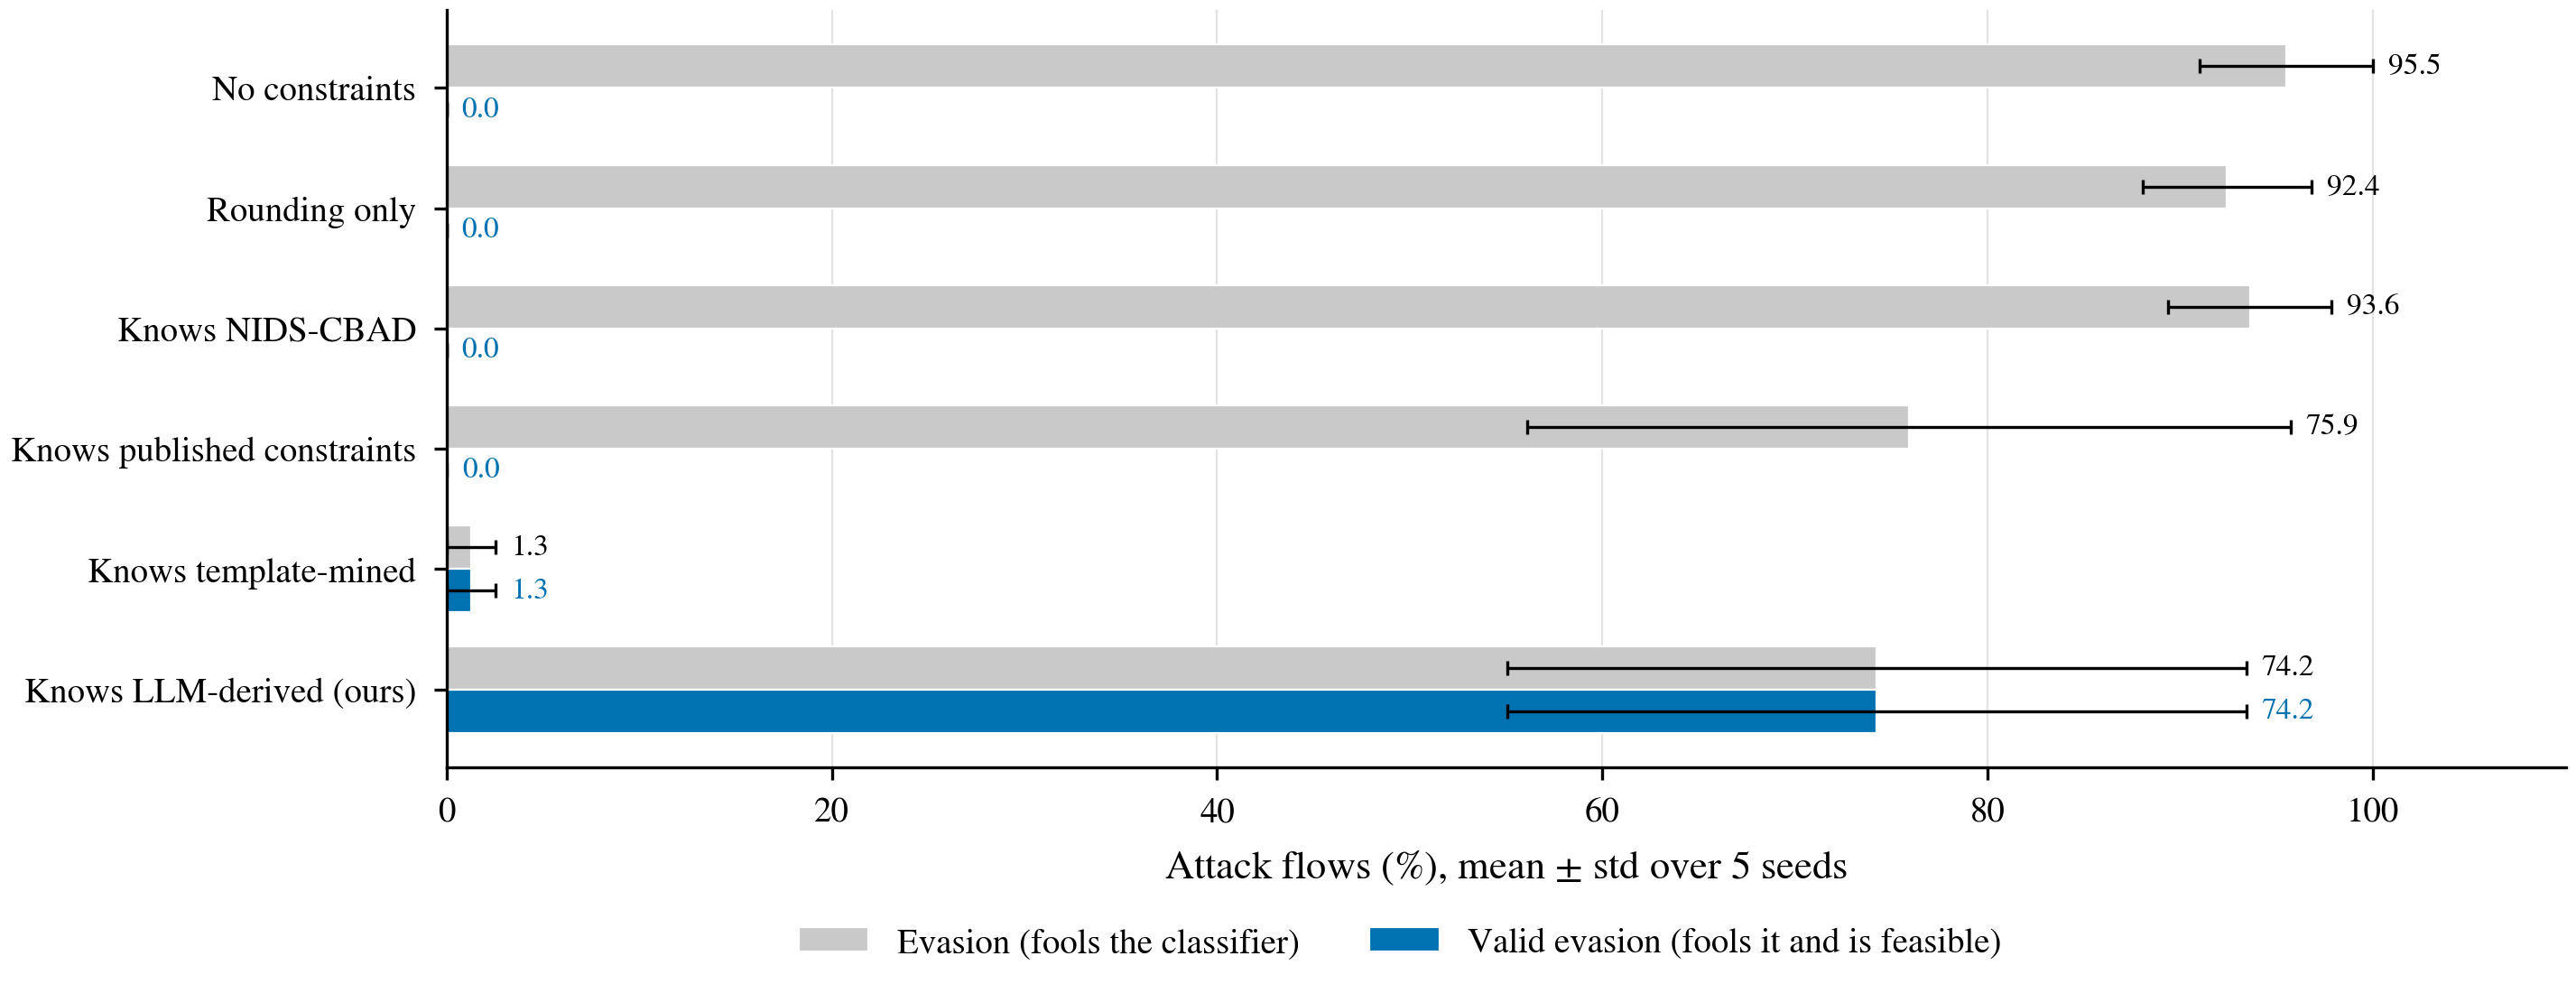


Saved PNG files (pixels at 600 dpi):
  fig1_pipeline.png                3365 x 1052 px  (5.61 x 1.75 in)
  fig2_cbad.png                    4281 x 1516 px  (7.13 x 2.53 in)
  fig3_funnel.png                  2088 x 1606 px  (3.48 x 2.68 in)
  fig4_transfer_fpr.png            4281 x 1305 px  (7.13 x 2.17 in)
  fig5_adaptive_attackers.png      4281 x 1636 px  (7.13 x 2.73 in)
  fig6_threshold_sensitivity.png   2085 x 1845 px  (3.48 x 3.08 in)
Cell 19b finished: figures fixed and resolution verified.


In [ ]:
# Cell 19b - Figure fixes: Figure 1 (left box clipped), Figure 2a (label crossed by the dashed line, invisible zero bars), Figure 5 (empty right margin); sharper inline previews; pixel-size check of every saved PNG

from PIL import Image
%config InlineBackend.figure_format = 'retina'
mpl.rcParams['figure.dpi'] = 200  # sharper notebook previews (saved files are unaffected: PNG/TIFF 600 dpi, PDF vector)

def inside_check(fig, name):
    # Warn if any text or legend extends beyond the figure canvas
    fig.canvas.draw()
    r, W, H = fig.canvas.get_renderer(), *fig.canvas.get_width_height()
    out = []
    for ax in fig.axes:
        for t in list(ax.texts) + ([ax.get_legend()] if ax.get_legend() else []):
            bb = t.get_bbox_patch().get_window_extent(r) if hasattr(t, 'get_bbox_patch') and t.get_bbox_patch() else t.get_window_extent(r)
            if bb.x0 < 0 or bb.y0 < 0 or bb.x1 > W or bb.y1 > H:
                out.append(getattr(t, 'get_text', lambda: 'legend')()[:25])
    print(f'[{name}] elements outside the canvas: {len(out)}' + (f' -> {out}' if out else ''))

# ---------- Figure 1 ----------
fig, ax = plt.subplots(figsize=(COL2, 2.2))
ax.set_xlim(-0.03, 1.03); ax.set_ylim(0, 1); ax.axis('off')
top = [node(x, 0.68, t, '#C6DCF0' if i == 4 else '#E3EEF8', OI['blue'], bold=(i == 4))
       for i, (x, t) in enumerate(zip([0.085, 0.295, 0.515, 0.72, 0.905], top_txt))]
bot = [node(x, 0.18, t, '#F6CDB8' if i == 2 else '#FBE7DD', OI['red'], bold=(i == 2))
       for i, (x, t) in enumerate(zip([0.085, 0.475, 0.905], bot_txt))]
ax.text(-0.02, 0.99, '(a) Proposed: documentation-driven proposal + data falsification', fontsize=7, style='italic', va='top')
ax.text(-0.02, 0.42, '(b) Baselines: constraints learned from data', fontsize=7, style='italic', va='top')
fig.canvas.draw()
rend = fig.canvas.get_renderer()
inv_t = ax.transData.inverted()
for row, col in [(top, OI['blue']), (bot, OI['red'])]:
    for a_, b_ in zip(row[:-1], row[1:]):
        _, ax1, y = edges(a_)
        bx0, _, _ = edges(b_)
        ax.annotate('', xy=(bx0 - 0.004, y), xytext=(ax1 + 0.004, y),
                    arrowprops=dict(arrowstyle='-|>', lw=0.8, color=col, mutation_scale=7))
inside_check(fig, 'fig1_pipeline')
save(fig, 'fig1_pipeline')

# ---------- Figure 2 ----------
fig, (a, b) = plt.subplots(1, 2, figsize=(COL2, 2.55), layout='constrained')
eps_vals = sorted(f2['eps'].unique()); w = 0.26; xs = np.arange(len(eps_vals))
for k, (flows, col, lab) in enumerate([('all', OI['grey'], 'All attack flows'), ('TCP', OI['orange'], 'TCP flows'),
                                       ('non-TCP', OI['blue'], 'Non-TCP flows')]):
    vals = [f2[(f2.eps == e) & (f2.flows == flows)]['CBAD_detection_%'].iloc[0] for e in eps_vals]
    a.bar(xs + (k - 1) * w, vals, w, color=col, label=lab, edgecolor='white', lw=0.4)
    if flows == 'TCP':  # zero-height bars: show the value explicitly
        for x, v in zip(xs, vals):
            a.annotate(f'{v:.0f}', (x, v), xytext=(0, 1.5), textcoords='offset points', ha='center', va='bottom',
                       fontsize=6.2, color=OI['orange'], weight='bold')
share = f2[(f2.eps == eps_vals[0]) & (f2.flows == 'all')]['CBAD_detection_%'].iloc[0]
a.axhline(share, color=OI['black'], ls='--', lw=0.7)
a.set_xlim(-0.55, len(eps_vals) + 0.55)
a.text(len(eps_vals) - 0.48, share + 2.5, f'non-TCP share\nof attack flows\n= {share:.2f}%', fontsize=6.2,
       ha='left', va='bottom')
a.set_xticks(xs); a.set_xticklabels([f'$\\epsilon$ = {e:g}' for e in eps_vals])
a.set_ylabel('NIDS-CBAD detection (%)'); a.set_ylim(0, 105)
a.set_title('(a) Detection equals the share of non-TCP flows')
a.legend(loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=3, handlelength=1.0, columnspacing=0.8)

settings = ['paper', 'practical', 'aware']; atks = ['PGD', 'JSMA']; xs = np.arange(len(settings)); w = 0.34
for k, (atk, col) in enumerate(zip(atks, [OI['blue'], OI['green']])):
    vals = [t3[(t3.setting == s) & (t3.attack == atk)]['undetected_evasion_%'].iloc[0] for s in settings]
    bars = b.bar(xs + (k - 0.5) * w, vals, w, color=col, label=atk, edgecolor='white', lw=0.4)
    for rr, v in zip(bars, vals):
        b.annotate(f'{v:.1f}', (rr.get_x() + rr.get_width() / 2, v), xytext=(0, 1.5), textcoords='offset points',
                   ha='center', va='bottom', fontsize=6)
b.set_xticks(xs); b.set_xticklabels(['Paper setting', 'Practical', 'Defense-aware'])
b.set_ylabel('Undetected evasion (%)'); b.set_ylim(0, 108)
b.set_title('(b) Evasion that NIDS-CBAD misses')
b.legend(loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=2)
inside_check(fig, 'fig2_cbad')
save(fig, 'fig2_cbad')

# ---------- Figure 5 ----------
fig, ax = plt.subplots(figsize=(COL2, 2.75), layout='constrained')
ys = np.arange(len(att_order)); h = 0.36
for off, colname, col, lab in [(-h / 2, 'evasion_%', '#C9C9C9', 'Evasion (fools the classifier)'),
                               (h / 2, 'valid evasion|LLM all %', OI['blue'], 'Valid evasion (fools it and is feasible)')]:
    mv, sv = g[(colname, 'mean')].values, g[(colname, 'std')].fillna(0).values
    ax.barh(ys + off, mv, h, xerr=sv, color=col, label=lab, edgecolor='white', lw=0.4,
            error_kw={'lw': 0.6, 'capsize': 1.5, 'capthick': 0.6})
    for y, v, s_ in zip(ys, mv, sv):
        ax.annotate(f'{v:.1f}', (v + s_, y + off), xytext=(3, 0), textcoords='offset points', va='center', ha='left',
                    fontsize=6, color=OI['blue'] if col == OI['blue'] else OI['black'])
ax.set_yticks(ys); ax.set_yticklabels(att_names); ax.invert_yaxis()
ax.set_xlim(0, 110); ax.set_xticks(range(0, 101, 20))
ax.set_xlabel('Attack flows (%), mean $\\pm$ std over 5 seeds')
ax.legend(loc='upper center', bbox_to_anchor=(0.45, -0.17), ncol=2)
ax.grid(axis='y', visible=False)
inside_check(fig, 'fig5_adaptive_attackers')
save(fig, 'fig5_adaptive_attackers')

# ---------- Resolution of the saved files ----------
print('\nSaved PNG files (pixels at 600 dpi):')
for f in sorted(glob.glob(os.path.join(FIG, '*.png'))):
    w_px, h_px = Image.open(f).size
    print(f'  {os.path.basename(f):32s} {w_px} x {h_px} px  ({w_px / 600:.2f} x {h_px / 600:.2f} in)')
print('Cell 19b finished: figures fixed and resolution verified.')